# 03 — Supervisionado: pilotos com coorte provisória

## Objetivo

Validar o fluxo supervisionado com a coorte provisória sem transformar resultados provisórios em conclusões finais.

Este notebook:

- respeita `configs/supervised.yaml` como fonte de decisões;
- usa a divisão principal aleatória 70%/15%/15%, estratificada por alvo e ano;
- mantém identificadores repetidos na mesma partição;
- bloqueia qualquer uso do teste nesta etapa;
- ajusta imputação, codificação e escala somente no treino;
- executa primeiro o Dummy e uma regressão logística piloto;
- registra métricas apenas na validação;
- marca todas as saídas como provisórias.

> **Limite desta versão:** não realiza calibração, escolha de limiar, tuning, análise final por subgrupo nem abertura do teste.

## 1. Bootstrap, ambiente e imports

A célula localiza automaticamente a raiz do projeto. Para validação técnica isolada, o notebook também aceita `SRAG_NOTEBOOK_SMOKE=1`, usando dados sintéticos sem acessar o Parquet real.

In [1]:
from pathlib import Path
import hashlib
import json
import os
import platform
import sys
import time
import warnings

import numpy as np
import pandas as pd
from IPython.display import display


def encontrar_raiz_projeto() -> Path:
    atual = Path.cwd().resolve()
    for pasta in [atual, *atual.parents]:
        if (pasta / "src").is_dir() and (pasta / "configs").is_dir():
            return pasta
    if os.getenv("SRAG_NOTEBOOK_SMOKE") == "1":
        return atual
    raise FileNotFoundError("Não foi possível localizar a raiz do projeto.")


ROOT_DIR = encontrar_raiz_projeto()
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

SMOKE_MODE = os.getenv("SRAG_NOTEBOOK_SMOKE") == "1"
STATUS_COORTE = "provisoria"
VERSAO_EXECUCAO = "piloto_v1"
SEED_FALLBACK = 42

print("ROOT_DIR:", ROOT_DIR)
print("SMOKE_MODE:", SMOKE_MODE)
print("Python:", sys.version.split()[0])
print("Sistema:", platform.system(), platform.release())

ROOT_DIR: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador
SMOKE_MODE: False
Python: 3.14.7
Sistema: Windows 11


## 2. Imports do projeto e contrato ativo

No projeto real, esta célula reutiliza configuração, leakage, métricas, modelos e registro de execução existentes em `src/`. No modo de smoke test, somente as dependências públicas necessárias são carregadas.

In [2]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    brier_score_loss,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

if not SMOKE_MODE:
    from src.utils import config as C
    from src.utils import env
    from src.utils.reproducibility import Run
    from src.evaluation.leakage import check_leakage
    from src.evaluation.metrics import metricas_completas
    from src.models.pipeline import criar_alvo_binario

    env.carregar_dotenv()
    env.garantir_diretorios()
    CFG = C.carregar_supervised()
    SEED = int(C.SEED)
    TABLES_DIR = C.TABLES_DIR
    PREDICTIONS_DIR = C.PREDICTIONS_DIR
    RUNS_DIR = C.RUNS_DIR
else:
    CFG = {
        "seed": 42,
        "target": {"coluna": "evolucao", "coluna_modelagem": "alvo_obito_srag", "positivos": [2.0], "negativos": [1.0]},
        "coluna_tempo": "dt_interna",
        "periodo": {"coluna_ano": "ano_internacao", "ano_inicial": 2019, "ano_final": 2026, "anos_parciais": [2026]},
        "features": {
            "numericas": ["idade_anos", "dias_sintomas_ate_internacao"],
            "categoricas": ["sexo_categoria", "febre", "tosse", "dispneia", "diabetes"],
            "final": None,
            "proibidas": ["evolucao", "alvo_obito_srag", "dt_evoluca", "dt_encerra", "dt_digita", "cluster"],
        },
        "temporal": {
            "modo": "aleatorio_estratificado",
            "coluna_estratificacao_temporal": "ano_internacao",
            "coluna_estratificacao_alvo": "alvo_obito_srag",
            "coluna_particao": "particao",
            "seed": 42,
            "fracao": {"treino": 0.70, "validacao": 0.15, "holdout": 0.15},
        },
        "missingness": {"categoricas": {"valor_ausente": "AUSENTE"}},
        "models": {"baseline": {"strategy": "prior"}, "logistic": {"max_iter": 1000, "class_weight": "balanced"}},
        "limiar": {"default": 0.5},
    }
    SEED = SEED_FALLBACK
    TABLES_DIR = ROOT_DIR / "outputs" / "tables"
    PREDICTIONS_DIR = ROOT_DIR / "outputs" / "predictions"
    RUNS_DIR = ROOT_DIR / "outputs" / "runs"

for pasta in (TABLES_DIR, PREDICTIONS_DIR, RUNS_DIR):
    pasta.mkdir(parents=True, exist_ok=True)

print("Seed:", SEED)
print("Modo de split:", CFG["temporal"]["modo"])
print("Alvo bruto:", CFG["target"]["coluna"])
print("Coluna temporal:", CFG["coluna_tempo"])

Seed: 42
Modo de split: aleatorio_estratificado
Alvo bruto: evolucao
Coluna temporal: dt_interna


## 3. Resolver e carregar a coorte provisória

A resolução fica centralizada nesta célula. Quando a coorte permanente chegar, a troca deve ocorrer apenas aqui ou no loader oficial, sem reescrever o restante do notebook.

In [3]:
CANDIDATOS_COORTE = [
    ROOT_DIR / "data" / "analytical" / "coorte_provisoria.parquet",
    ROOT_DIR / "data" / "analytical" / "coorte_provisoria_b.parquet",
    ROOT_DIR / "data" / "analytical" / "coorte.parquet",
]


def criar_coorte_sintetica(n: int = 6000, seed: int = 42) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    anos = rng.choice(np.arange(2019, 2027), size=n, p=[0.04, 0.17, 0.22, 0.18, 0.12, 0.11, 0.10, 0.06])
    idade = np.clip(rng.normal(48, 27, size=n), 0, 100)
    sexo = rng.choice(["M", "F", "I"], size=n, p=[0.52, 0.479, 0.001])
    febre = rng.choice(["1", "2", "9", None], size=n, p=[0.55, 0.30, 0.03, 0.12])
    tosse = rng.choice(["1", "2", "9", None], size=n, p=[0.66, 0.22, 0.02, 0.10])
    dispneia = rng.choice(["1", "2", "9", None], size=n, p=[0.58, 0.27, 0.02, 0.13])
    diabetes = rng.choice(["1", "2", "9", None], size=n, p=[0.16, 0.25, 0.01, 0.58])
    dias = np.clip(rng.normal(6, 4, size=n), 0, 40)
    logit = -4.2 + 0.045 * idade + 0.7 * (np.asarray(dispneia) == "1") + 0.55 * (np.asarray(diabetes) == "1")
    prob = 1 / (1 + np.exp(-logit))
    alvo = rng.binomial(1, prob)
    datas = pd.to_datetime(pd.Series(anos).astype(str) + "-01-01") + pd.to_timedelta(rng.integers(0, 365, size=n), unit="D")
    ids = np.arange(n).astype(str)
    ids[:20] = np.repeat(np.arange(10).astype(str), 2)
    return pd.DataFrame({
        "nu_notific": ids,
        "dt_interna": datas,
        "ano_internacao": anos,
        "idade_anos": idade,
        "dias_sintomas_ate_internacao": dias,
        "sexo_categoria": sexo,
        "febre": febre,
        "tosse": tosse,
        "dispneia": dispneia,
        "diabetes": diabetes,
        "evolucao": np.where(alvo == 1, 2.0, 1.0),
        "alvo_obito_srag": alvo.astype("int8"),
        "status_coorte": "sintetica_smoke",
    })


if SMOKE_MODE:
    CAMINHO_COORTE = None
    df = criar_coorte_sintetica(seed=SEED)
else:
    existentes = [p for p in CANDIDATOS_COORTE if p.exists()]
    if not existentes:
        raise FileNotFoundError(
            "Nenhuma coorte provisória foi encontrada. Candidatos:\n"
            + "\n".join(f"- {p}" for p in CANDIDATOS_COORTE)
        )
    CAMINHO_COORTE = existentes[0]
    df = pd.read_parquet(CAMINHO_COORTE)

print("Fonte:", CAMINHO_COORTE if CAMINHO_COORTE else "dados sintéticos de smoke test")
print("Dimensão:", df.shape)
display(df.head(3))

Fonte: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\data\analytical\coorte_provisoria_b.parquet
Dimensão: (3915136, 125)


,id_registro,ano_arquivo,data_snapshot,arquivo_origem,nosocomial,nu_notific,dt_notific,dt_sin_pri,sem_pri,hospital,...,flag_dt_notific_ausente,flag_nosocomial,flag_intervalo_negativo_sem_nosocomial,periodo_incompleto,faixa_dias_sintomas_ate_internacao,quantidade_ocorrencias_nu_notific,flag_nu_notific_repetido,flag_nu_notific_ausente,status_coorte,data_corte_coorte
0,0,2026,2026-09-28,INFLUD26-28-09-2026.parquet,2,31781201987679,2026-06-11,2026-06-02,23,1,...,0,0,0,1,8_a_14,1,0,0,provisoria_pessoa_b,2026-09-28
1,4,2026,2026-09-28,INFLUD26-28-09-2026.parquet,2,31773493207022,2026-03-14,2026-03-09,11,1,...,0,0,0,1,1_a_7,1,0,0,provisoria_pessoa_b,2026-09-28
2,5,2026,2026-09-28,INFLUD26-28-09-2026.parquet,1,31774542694487,2026-03-23,2026-03-18,12,1,...,0,1,0,1,zero,1,0,0,provisoria_pessoa_b,2026-09-28


## 4. Compatibilidade controlada da coorte provisória

Esta célula aceita somente aliases explícitos e auditáveis. Ela não cria informação clínica nova. O objetivo é absorver diferenças conhecidas de nomenclatura entre a coorte provisória e o contrato atual.

In [6]:
# Aliases aceitos somente quando representam o mesmo conceito.
ALIASES_COMPATIBILIDADE = {
    "dt_interna_convertida": "dt_interna",
    "cs_sexo": "sexo_categoria",
    "intervalo_sint_interna_dias": "dias_sintomas_ate_internacao",
}

ajustes_aplicados = []

for origem, destino in ALIASES_COMPATIBILIDADE.items():
    if destino not in df.columns and origem in df.columns:
        df[destino] = df[origem]
        ajustes_aplicados.append(
            {
                "tipo": "alias",
                "origem": origem,
                "destino": destino,
            }
        )

COLUNA_TEMPO = str(CFG["coluna_tempo"])
COLUNA_ANO = str(CFG["periodo"]["coluna_ano"])
ALVO_BRUTO = str(CFG["target"]["coluna"])
ALVO_MODELO = str(CFG["target"]["coluna_modelagem"])
COLUNA_PARTICAO = str(CFG["temporal"]["coluna_particao"])

# ------------------------------------------------------------------
# Engenharia mínima de atributos.
# Reutiliza as funções oficiais do projeto e cria somente as colunas
# exigidas pelo piloto que ainda não existem na coorte provisória.
# ------------------------------------------------------------------
if "idade_anos" not in df.columns:
    entradas_idade = [
        "nu_idade_n",
        "tp_idade",
    ]

    faltantes_idade = [
        coluna
        for coluna in entradas_idade
        if coluna not in df.columns
    ]

    if faltantes_idade:
        raise KeyError(
            "Não foi possível derivar idade_anos. "
            "Entradas ausentes: "
            f"{faltantes_idade}"
        )

    if SMOKE_MODE:
        idade_valor = pd.to_numeric(
            df["nu_idade_n"],
            errors="coerce",
        )
        idade_tipo = pd.to_numeric(
            df["tp_idade"],
            errors="coerce",
        )
        idade_anos = pd.Series(
            np.nan,
            index=df.index,
            dtype="float64",
        )
        idade_anos.loc[idade_tipo.eq(1)] = (
            idade_valor.loc[idade_tipo.eq(1)]
            / 365.25
        )
        idade_anos.loc[idade_tipo.eq(2)] = (
            idade_valor.loc[idade_tipo.eq(2)]
            / 12.0
        )
        idade_anos.loc[idade_tipo.eq(3)] = (
            idade_valor.loc[idade_tipo.eq(3)]
        )
        idade_anos = idade_anos.where(
            idade_anos.between(
                0,
                120,
                inclusive="both",
            )
        )
        df["idade_anos"] = idade_anos
    else:
        from src.features import idade_em_anos

        df["idade_anos"] = idade_em_anos(
            df
        )

    ajustes_aplicados.append(
        {
            "tipo": "derivacao",
            "origem": "nu_idade_n + tp_idade",
            "destino": "idade_anos",
        }
    )

if (
    "dias_sintomas_ate_internacao" not in df.columns
    and "intervalo_sint_interna_dias" not in df.columns
):
    entradas_intervalo = [
        "dt_sin_pri",
        "dt_interna",
    ]

    faltantes_intervalo = [
        coluna
        for coluna in entradas_intervalo
        if coluna not in df.columns
    ]

    if faltantes_intervalo:
        raise KeyError(
            "Não foi possível derivar o intervalo entre "
            "sintomas e internação. Entradas ausentes: "
            f"{faltantes_intervalo}"
        )

    if SMOKE_MODE:
        dt_sintomas = pd.to_datetime(
            df["dt_sin_pri"],
            errors="coerce",
        )
        dt_internacao = pd.to_datetime(
            df["dt_interna"],
            errors="coerce",
        )
        intervalo = (
            dt_internacao
            .sub(dt_sintomas)
            .dt.days
            .astype("float64")
        )
        intervalo = intervalo.where(
            intervalo.between(
                0,
                60,
                inclusive="both",
            )
        )
        df["intervalo_sint_interna_dias"] = intervalo
    else:
        from src.features import intervalo_sintomas_internacao

        intervalo_derivado = (
            intervalo_sintomas_internacao(
                df
            )
        )
        df["intervalo_sint_interna_dias"] = (
            intervalo_derivado[
                "intervalo_sint_interna_dias"
            ]
        )
        if "flag_intervalo_invalido" not in df.columns:
            df["flag_intervalo_invalido"] = (
                intervalo_derivado[
                    "flag_intervalo_invalido"
                ]
            )

    ajustes_aplicados.append(
        {
            "tipo": "derivacao",
            "origem": "dt_sin_pri + dt_interna",
            "destino": "intervalo_sint_interna_dias",
        }
    )

if (
    "dias_sintomas_ate_internacao" not in df.columns
    and "intervalo_sint_interna_dias" in df.columns
):
    df["dias_sintomas_ate_internacao"] = (
        df["intervalo_sint_interna_dias"]
    )
    ajustes_aplicados.append(
        {
            "tipo": "alias_derivada",
            "origem": "intervalo_sint_interna_dias",
            "destino": "dias_sintomas_ate_internacao",
        }
    )

# ------------------------------------------------------------------
# Tempo e ano de internação.
# ------------------------------------------------------------------
if (
    COLUNA_TEMPO not in df.columns
    and "dt_interna_convertida" in df.columns
):
    df[COLUNA_TEMPO] = (
        df["dt_interna_convertida"]
    )
    ajustes_aplicados.append(
        {
            "tipo": "alias",
            "origem": "dt_interna_convertida",
            "destino": COLUNA_TEMPO,
        }
    )

if COLUNA_TEMPO not in df.columns:
    raise KeyError(
        "A coluna temporal configurada não existe: "
        f"{COLUNA_TEMPO}"
    )

df[COLUNA_TEMPO] = pd.to_datetime(
    df[COLUNA_TEMPO],
    errors="coerce",
)

if COLUNA_ANO not in df.columns:
    df[COLUNA_ANO] = (
        df[COLUNA_TEMPO]
        .dt.year
        .astype("Int64")
    )
    ajustes_aplicados.append(
        {
            "tipo": "derivacao",
            "origem": COLUNA_TEMPO,
            "destino": COLUNA_ANO,
        }
    )

# ------------------------------------------------------------------
# Alvo binário.
# ------------------------------------------------------------------
if ALVO_MODELO not in df.columns:
    if ALVO_BRUTO not in df.columns:
        raise KeyError(
            "Nem o alvo derivado nem o alvo bruto foram "
            "encontrados. Colunas esperadas: "
            f"{ALVO_MODELO}, {ALVO_BRUTO}"
        )

    positivos = {
        float(valor)
        for valor in CFG["target"]["positivos"]
    }
    negativos = {
        float(valor)
        for valor in CFG["target"]["negativos"]
    }

    valores_alvo = pd.to_numeric(
        df[ALVO_BRUTO],
        errors="coerce",
    )

    alvo_binario = pd.Series(
        pd.NA,
        index=df.index,
        dtype="Int8",
    )
    alvo_binario.loc[
        valores_alvo.isin(negativos)
    ] = 0
    alvo_binario.loc[
        valores_alvo.isin(positivos)
    ] = 1

    df[ALVO_MODELO] = alvo_binario

    ajustes_aplicados.append(
        {
            "tipo": "derivacao",
            "origem": ALVO_BRUTO,
            "destino": ALVO_MODELO,
        }
    )

print("Ajustes aplicados:")

display(
    pd.DataFrame(ajustes_aplicados)
    if ajustes_aplicados
    else pd.DataFrame(
        {
            "status": [
                "nenhum ajuste necessário"
            ]
        }
    )
)

print(
    "idade_anos disponível:",
    "idade_anos" in df.columns,
)
print(
    "dias_sintomas_ate_internacao disponível:",
    "dias_sintomas_ate_internacao" in df.columns,
)


Ajustes aplicados:


,tipo,origem,destino
0,derivacao,nu_idade_n + tp_idade,idade_anos


idade_anos disponível: True
dias_sintomas_ate_internacao disponível: True


## 5. Contrato de features e validação estrutural

Enquanto `features.final` estiver vazio, o piloto usa a concatenação das listas numérica e categórica. A lista final permanece pendente até a coorte definitiva.

In [7]:
features_cfg = CFG["features"]
FEATURES_NUMERICAS = list(features_cfg.get("numericas") or [])
FEATURES_CATEGORICAS = list(features_cfg.get("categoricas") or [])
FEATURES_FINAIS_CFG = features_cfg.get("final")
FEATURES_PILOTO = list(FEATURES_FINAIS_CFG or (FEATURES_NUMERICAS + FEATURES_CATEGORICAS))
PROIBIDAS = set(features_cfg.get("proibidas") or [])

faltantes = sorted(set(FEATURES_PILOTO) - set(df.columns))
vazamento_config = sorted(set(FEATURES_PILOTO) & PROIBIDAS)

contrato = pd.DataFrame({
    "item": [
        "coorte_nao_vazia",
        "dt_interna_disponivel",
        "dt_interna_sem_nulos",
        "ano_disponivel",
        "alvo_disponivel",
        "alvo_binario",
        "features_sem_proibidas",
        "features_presentes",
    ],
    "resultado": [
        not df.empty,
        COLUNA_TEMPO in df.columns,
        bool(df[COLUNA_TEMPO].notna().all()),
        COLUNA_ANO in df.columns,
        ALVO_MODELO in df.columns,
        set(pd.Series(df[ALVO_MODELO]).dropna().astype(int).unique()).issubset({0, 1}),
        not vazamento_config,
        not faltantes,
    ],
})

display(contrato)
print("Features piloto:", len(FEATURES_PILOTO))
print("Faltantes:", faltantes)
print("Vazamento na configuração:", vazamento_config)

if faltantes:
    raise KeyError(
        "A coorte provisória não atende ao contrato de features. "
        f"Colunas faltantes: {faltantes}. Corrija aliases ou a geração da coorte, "
        "sem relaxar silenciosamente o contrato."
    )
if vazamento_config:
    raise RuntimeError(f"Features proibidas presentes no contrato: {vazamento_config}")
if not contrato["resultado"].all():
    falhas = contrato.loc[~contrato["resultado"], "item"].tolist()
    raise RuntimeError(f"Falhas no contrato estrutural: {falhas}")

,item,resultado
0,coorte_nao_vazia,True
1,dt_interna_disponivel,True
2,dt_interna_sem_nulos,True
3,ano_disponivel,True
4,alvo_disponivel,True
5,alvo_binario,True
6,features_sem_proibidas,True
7,features_presentes,True


Features piloto: 31
Faltantes: []
Vazamento na configuração: []


## 6. Auditoria de tipos, alvo, período e ausência

A célula descreve a base que efetivamente entrará no piloto. Nenhuma decisão de exclusão de feature é tomada aqui.

In [8]:
resumo_base = pd.DataFrame({
    "metrica": [
        "status_coorte", "versao_execucao", "linhas", "colunas",
        "data_minima", "data_maxima", "ano_minimo", "ano_maximo",
        "positivos", "negativos", "prevalencia_positiva",
    ],
    "valor": [
        STATUS_COORTE, VERSAO_EXECUCAO, len(df), df.shape[1],
        df[COLUNA_TEMPO].min(), df[COLUNA_TEMPO].max(),
        int(df[COLUNA_ANO].min()), int(df[COLUNA_ANO].max()),
        int((df[ALVO_MODELO] == 1).sum()), int((df[ALVO_MODELO] == 0).sum()),
        float(pd.to_numeric(df[ALVO_MODELO], errors="coerce").mean()),
    ],
})

ausencia_features = pd.DataFrame({
    "feature": FEATURES_PILOTO,
    "tipo_configurado": ["numerica" if c in FEATURES_NUMERICAS else "categorica" for c in FEATURES_PILOTO],
    "dtype": [str(df[c].dtype) for c in FEATURES_PILOTO],
    "ausentes": [int(df[c].isna().sum()) for c in FEATURES_PILOTO],
    "percentual_ausente": [float(df[c].isna().mean() * 100) for c in FEATURES_PILOTO],
    "cardinalidade": [int(df[c].nunique(dropna=True)) for c in FEATURES_PILOTO],
}).sort_values(["percentual_ausente", "feature"], ascending=[False, True])

display(resumo_base)
display(ausencia_features.head(20))

,metrica,valor
0,status_coorte,provisoria
1,versao_execucao,piloto_v1
2,linhas,3915136
3,colunas,127
4,data_minima,2019-01-01 00:00:00
5,data_maxima,2026-09-25 00:00:00
6,ano_minimo,2019
7,ano_maximo,2026
8,positivos,856185
9,negativos,3058951


,feature,tipo_configurado,dtype,ausentes,percentual_ausente,cardinalidade
18,puerpera,categorica,str,2502552,63.919925,3
22,hepatica,categorica,str,2500628,63.870783,3
21,sind_down,categorica,str,2499618,63.844985,3
20,hematologi,categorica,str,2495230,63.732907,3
27,imunodepre,categorica,str,2477933,63.291109,3
28,renal,categorica,str,2473461,63.176886,3
25,neurologic,categorica,str,2456387,62.740783,3
23,asma,categorica,str,2456205,62.736135,3
26,pneumopati,categorica,str,2455540,62.719149,3
29,obesidade,categorica,str,2450768,62.597264,3


## 7. Preparar a base elegível e a chave de grupo

Linhas sem rótulo ou sem data não são usadas no piloto. O identificador técnico é mantido apenas para impedir que ocorrências repetidas sejam distribuídas entre partições.

In [9]:
colunas_necessarias = list(dict.fromkeys(
    FEATURES_PILOTO + [ALVO_MODELO, ALVO_BRUTO, COLUNA_TEMPO, COLUNA_ANO]
    + (["nu_notific"] if "nu_notific" in df.columns else [])
))
base_modelagem = df[colunas_necessarias].copy()
base_modelagem = base_modelagem.loc[
    base_modelagem[ALVO_MODELO].notna() & base_modelagem[COLUNA_TEMPO].notna()
].reset_index(drop=True)
base_modelagem[ALVO_MODELO] = base_modelagem[ALVO_MODELO].astype("int8")
base_modelagem[COLUNA_ANO] = pd.to_numeric(base_modelagem[COLUNA_ANO], errors="raise").astype("int16")

if "nu_notific" in base_modelagem.columns:
    id_texto = base_modelagem["nu_notific"].astype("string").str.strip()
    ausente_id = id_texto.isna() | id_texto.eq("")
    id_texto = id_texto.mask(ausente_id, "LINHA_" + base_modelagem.index.astype(str))
    base_modelagem["grupo_split"] = id_texto
else:
    base_modelagem["grupo_split"] = "LINHA_" + base_modelagem.index.astype(str)

base_modelagem["estrato_split"] = (
    base_modelagem[COLUNA_ANO].astype(str)
    + "__y"
    + base_modelagem[ALVO_MODELO].astype(str)
)

print("Linhas elegíveis:", len(base_modelagem))
print("Grupos únicos:", base_modelagem["grupo_split"].nunique())
print("Estratos:", base_modelagem["estrato_split"].nunique())
display(base_modelagem["estrato_split"].value_counts().sort_index().to_frame("n"))

Linhas elegíveis: 3915136
Grupos únicos: 3915121
Estratos: 16


,n
estrato_split,
2019__y0,38292
2019__y1,5221
2020__y0,705699
2020__y1,274113
2021__y0,1062924
2021__y1,417291
2022__y0,389547
2022__y1,86433
2023__y0,217667


In [13]:
from pathlib import Path
import numpy as np
import pandas as pd


POLITICA_CONFLITOS_SPLIT = "quarentena_provisoria"
COLUNA_GRUPO_SPLIT = "grupo_split"
COLUNA_ESTRATO_SPLIT = "estrato_split"

COLUNAS_AUDITORIA_CONFLITOS = [
    COLUNA_GRUPO_SPLIT,
    COLUNA_ESTRATO_SPLIT,
    "nu_notific",
    "ano_internacao",
    "alvo_obito_srag",
    "evolucao",
    "dt_interna",
]

colunas_split_ausentes = [
    coluna
    for coluna in [
        COLUNA_GRUPO_SPLIT,
        COLUNA_ESTRATO_SPLIT,
    ]
    if coluna not in base_modelagem.columns
]

if colunas_split_ausentes:
    raise KeyError(
        "A base de modelagem não contém as colunas necessárias "
        f"para auditar o split: {colunas_split_ausentes}"
    )

if base_modelagem[COLUNA_GRUPO_SPLIT].isna().any():
    raise ValueError(
        "A coluna grupo_split contém valores ausentes. "
        "Corrija a formação do identificador antes do split."
    )

if base_modelagem[COLUNA_ESTRATO_SPLIT].isna().any():
    raise ValueError(
        "A coluna estrato_split contém valores ausentes. "
        "Corrija ano e alvo antes do split."
    )

mascara_grupos_repetidos_split = (
    base_modelagem[COLUNA_GRUPO_SPLIT].duplicated(keep=False)
)

if mascara_grupos_repetidos_split.any():
    auditoria_estratos_por_grupo = (
        base_modelagem.loc[
            mascara_grupos_repetidos_split,
            [
                COLUNA_GRUPO_SPLIT,
                COLUNA_ESTRATO_SPLIT,
            ],
        ]
        .groupby(
            COLUNA_GRUPO_SPLIT,
            sort=False,
            observed=True,
        )
        .agg(
            quantidade_linhas=(COLUNA_ESTRATO_SPLIT, "size"),
            quantidade_estratos=(COLUNA_ESTRATO_SPLIT, "nunique"),
            estratos_observados=(
                COLUNA_ESTRATO_SPLIT,
                lambda serie: " | ".join(
                    sorted(
                        serie.astype("string").dropna().unique().tolist()
                    )
                ),
            ),
        )
        .reset_index()
    )
else:
    auditoria_estratos_por_grupo = pd.DataFrame(
        columns=[
            COLUNA_GRUPO_SPLIT,
            "quantidade_linhas",
            "quantidade_estratos",
            "estratos_observados",
        ]
    )

grupos_conflitantes_split = (
    auditoria_estratos_por_grupo.loc[
        auditoria_estratos_por_grupo["quantidade_estratos"].gt(1),
        COLUNA_GRUPO_SPLIT,
    ]
    .astype("string")
    .tolist()
)

colunas_auditoria_disponiveis = [
    coluna
    for coluna in COLUNAS_AUDITORIA_CONFLITOS
    if coluna in base_modelagem.columns
]

if grupos_conflitantes_split:
    mascara_conflitos_split = (
        base_modelagem[COLUNA_GRUPO_SPLIT]
        .astype("string")
        .isin(grupos_conflitantes_split)
    )

    registros_conflitantes_split = (
        base_modelagem.loc[
            mascara_conflitos_split,
            colunas_auditoria_disponiveis,
        ]
        .copy()
        .sort_values(
            [
                COLUNA_GRUPO_SPLIT,
                COLUNA_ESTRATO_SPLIT,
            ]
        )
        .reset_index(drop=False)
        .rename(columns={"index": "indice_original"})
    )

    resumo_conflitos_split = (
        registros_conflitantes_split.groupby(
            COLUNA_GRUPO_SPLIT,
            sort=True,
            observed=True,
        )
        .agg(
            quantidade_linhas=(COLUNA_ESTRATO_SPLIT, "size"),
            quantidade_estratos=(COLUNA_ESTRATO_SPLIT, "nunique"),
            estratos_observados=(
                COLUNA_ESTRATO_SPLIT,
                lambda serie: " | ".join(
                    sorted(
                        serie.astype("string").dropna().unique().tolist()
                    )
                ),
            ),
        )
        .reset_index()
    )

    diretorio_auditoria_split = Path(C.TABLES_DIR)
    diretorio_auditoria_split.mkdir(parents=True, exist_ok=True)

    caminho_registros_conflitantes = (
        diretorio_auditoria_split
        / "supervisionado_registros_conflitantes_split_provisorio.csv"
    )

    caminho_resumo_conflitos = (
        diretorio_auditoria_split
        / "supervisionado_resumo_conflitos_split_provisorio.csv"
    )

    registros_conflitantes_split.to_csv(
        caminho_registros_conflitantes,
        index=False,
        encoding="utf-8-sig",
    )

    resumo_conflitos_split.to_csv(
        caminho_resumo_conflitos,
        index=False,
        encoding="utf-8-sig",
    )

    if POLITICA_CONFLITOS_SPLIT != "quarentena_provisoria":
        raise ValueError(
            "A política configurada para conflitos de split não é suportada: "
            f"{POLITICA_CONFLITOS_SPLIT}"
        )

    quantidade_linhas_antes_quarentena = len(base_modelagem)

    base_modelagem = (
        base_modelagem.loc[
            ~mascara_conflitos_split
        ]
        .copy()
        .reset_index(drop=True)
    )

    quantidade_linhas_quarentena = (
        quantidade_linhas_antes_quarentena
        - len(base_modelagem)
    )

    if base_modelagem[COLUNA_GRUPO_SPLIT].astype("string").isin(
        grupos_conflitantes_split
    ).any():
        raise RuntimeError(
            "A quarentena não removeu todos os grupos conflitantes."
        )

    print("Conflitos de split encontrados e colocados em quarentena provisória.")
    print("Grupos conflitantes:", len(grupos_conflitantes_split))
    print("Linhas em quarentena:", quantidade_linhas_quarentena)
    print("Linhas restantes para o piloto:", len(base_modelagem))
    print("Auditoria detalhada:", caminho_registros_conflitantes)
    print("Resumo dos conflitos:", caminho_resumo_conflitos)

    display(resumo_conflitos_split)
    display(registros_conflitantes_split.head(50))

else:
    registros_conflitantes_split = pd.DataFrame(
        columns=["indice_original"] + colunas_auditoria_disponiveis
    )

    resumo_conflitos_split = pd.DataFrame(
        columns=[
            COLUNA_GRUPO_SPLIT,
            "quantidade_linhas",
            "quantidade_estratos",
            "estratos_observados",
        ]
    )

    print("Nenhum grupo conflitante foi encontrado para o split.")


# Validação final antes da célula de particionamento.
estratos_por_grupo_pos_quarentena = (
    base_modelagem.groupby(
        COLUNA_GRUPO_SPLIT,
        sort=False,
        observed=True,
    )[COLUNA_ESTRATO_SPLIT]
    .nunique(dropna=False)
)

quantidade_conflitos_pos_quarentena = int(
    estratos_por_grupo_pos_quarentena.gt(1).sum()
)

if quantidade_conflitos_pos_quarentena > 0:
    raise RuntimeError(
        "Ainda existem grupos associados a mais de um estrato após a auditoria: "
        f"{quantidade_conflitos_pos_quarentena}"
    )

print(
    "Base provisória pronta para o split agrupado. "
    "Nenhum grupo restante cruza combinações de ano e alvo."
)


Conflitos de split encontrados e colocados em quarentena provisória.
Grupos conflitantes: 2
Linhas em quarentena: 4
Linhas restantes para o piloto: 3915132
Auditoria detalhada: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\outputs\tables\supervisionado_registros_conflitantes_split_provisorio.csv
Resumo dos conflitos: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\outputs\tables\supervisionado_resumo_conflitos_split_provisorio.csv


,grupo_split,quantidade_linhas,quantidade_estratos,estratos_observados
0,31736866916969,2,2,2024__y0 | 2025__y0
1,31745324608735,2,2,2024__y1 | 2025__y1


,indice_original,grupo_split,estrato_split,nu_notific,ano_internacao,alvo_obito_srag,evolucao,dt_interna
0,653105,31736866916969,2024__y0,31736866916969,2024,0,1,2024-01-14
1,263526,31736866916969,2025__y0,31736866916969,2025,0,1,2025-01-14
2,483104,31745324608735,2024__y1,31745324608735,2024,1,2,2024-08-15
3,196104,31745324608735,2025__y1,31745324608735,2025,1,2,2025-04-16


Base provisória pronta para o split agrupado. Nenhum grupo restante cruza combinações de ano e alvo.


## 8. Criar a partição provisória persistível

A implementação faz a divisão no nível do identificador, preservando a composição conjunta de ano e alvo tanto quanto possível. O teste é criado e rotulado, mas não é acessado nas etapas de comparação.

In [14]:
def criar_particoes_agrupadas(
    base: pd.DataFrame,
    *,
    grupo: str,
    estrato: str,
    frac_treino: float,
    frac_validacao: float,
    frac_teste: float,
    seed: int,
) -> pd.Series:
    """
    Cria partições reproduzíveis por estrato, mantendo todas as linhas
    de um mesmo grupo na mesma partição.

    Implementação otimizada para bases com milhões de registros e
    identificadores majoritariamente únicos.
    """

    soma_fracoes = (
        frac_treino
        + frac_validacao
        + frac_teste
    )

    if not np.isclose(
        soma_fracoes,
        1.0,
    ):
        raise ValueError(
            "As frações do split precisam somar 1."
        )

    colunas_necessarias = {
        grupo,
        estrato,
    }

    colunas_ausentes = sorted(
        colunas_necessarias
        - set(base.columns)
    )

    if colunas_ausentes:
        raise KeyError(
            "Colunas necessárias ao split ausentes: "
            f"{colunas_ausentes}"
        )

    if base[grupo].isna().any():
        raise ValueError(
            f"A coluna de grupo {grupo!r} contém valores ausentes."
        )

    if base[estrato].isna().any():
        raise ValueError(
            f"A coluna de estrato {estrato!r} contém valores ausentes."
        )

    # ------------------------------------------------------------
    # 1. Validar somente os identificadores realmente repetidos.
    #
    # Não executamos uma função Python para cada um dos milhões
    # de identificadores quase únicos.
    # ------------------------------------------------------------

    mascara_grupos_repetidos = (
        base[grupo].duplicated(
            keep=False
        )
    )

    quantidade_linhas_repetidas = int(
        mascara_grupos_repetidos.sum()
    )

    quantidade_grupos_repetidos = int(
        base.loc[
            mascara_grupos_repetidos,
            grupo,
        ].nunique()
    )

    if quantidade_linhas_repetidas > 0:
        estratos_por_grupo_repetido = (
            base.loc[
                mascara_grupos_repetidos,
                [
                    grupo,
                    estrato,
                ],
            ]
            .groupby(
                grupo,
                sort=False,
                observed=True,
            )[estrato]
            .nunique(
                dropna=False
            )
        )

        grupos_com_estratos_conflitantes = (
            estratos_por_grupo_repetido.loc[
                estratos_por_grupo_repetido.gt(1)
            ]
        )

        if not grupos_com_estratos_conflitantes.empty:
            exemplo_conflitos = (
                grupos_com_estratos_conflitantes
                .head(10)
                .index
                .astype(str)
                .tolist()
            )

            raise ValueError(
                "Foram encontrados identificadores repetidos "
                "associados a mais de um estrato de ano e alvo. "
                "A regra desses registros precisa ser revisada "
                "antes do split. Exemplos: "
                f"{exemplo_conflitos}"
            )

    # ------------------------------------------------------------
    # 2. Construir uma linha por grupo.
    #
    # Como conflitos já foram bloqueados, basta preservar a primeira
    # ocorrência de cada grupo. Isso substitui o groupby com lambda.
    # ------------------------------------------------------------

    resumo_grupos = (
        base.loc[
            :,
            [
                grupo,
                estrato,
            ],
        ]
        .drop_duplicates(
            subset=grupo,
            keep="first",
        )
        .reset_index(
            drop=True
        )
    )

    quantidade_grupos = len(
        resumo_grupos
    )

    if quantidade_grupos == 0:
        raise ValueError(
            "Nenhum grupo disponível para criar as partições."
        )

    # Array object simples, evitando uma Series inicialmente cheia
    # de pd.NA para milhões de linhas.
    particoes_grupos = np.empty(
        quantidade_grupos,
        dtype=object,
    )

    particoes_grupos[:] = None

    rng = np.random.default_rng(
        seed
    )

    # ------------------------------------------------------------
    # 3. Dividir separadamente cada combinação de ano e alvo.
    #
    # O número de estratos é pequeno. O loop ocorre por estrato,
    # não por identificador.
    # ------------------------------------------------------------

    indices_por_estrato = (
        resumo_grupos.groupby(
            estrato,
            sort=False,
            observed=True,
        )
        .indices
    )

    diagnostico_estratos = []

    for valor_estrato, indices_bloco in (
        indices_por_estrato.items()
    ):
        indices = np.asarray(
            indices_bloco,
            dtype=np.int64,
        )

        indices = rng.permutation(
            indices
        )

        quantidade = len(
            indices
        )

        if quantidade == 0:
            continue

        quantidade_treino = int(
            np.floor(
                quantidade
                * frac_treino
            )
        )

        quantidade_validacao = int(
            np.floor(
                quantidade
                * frac_validacao
            )
        )

        # Para estratos com pelo menos três grupos, garantir presença
        # mínima em treino, validação e teste.
        if quantidade >= 3:
            quantidade_treino = max(
                quantidade_treino,
                1,
            )

            quantidade_validacao = max(
                quantidade_validacao,
                1,
            )

            quantidade_teste = (
                quantidade
                - quantidade_treino
                - quantidade_validacao
            )

            if quantidade_teste < 1:
                excesso = (
                    1
                    - quantidade_teste
                )

                reducao_treino = min(
                    excesso,
                    max(
                        quantidade_treino - 1,
                        0,
                    ),
                )

                quantidade_treino -= (
                    reducao_treino
                )

                excesso -= reducao_treino

                if excesso > 0:
                    quantidade_validacao -= (
                        excesso
                    )

        fim_treino = (
            quantidade_treino
        )

        fim_validacao = (
            quantidade_treino
            + quantidade_validacao
        )

        particoes_grupos[
            indices[:fim_treino]
        ] = "treino"

        particoes_grupos[
            indices[
                fim_treino:fim_validacao
            ]
        ] = "validacao"

        particoes_grupos[
            indices[fim_validacao:]
        ] = "teste"

        diagnostico_estratos.append(
            {
                "estrato": valor_estrato,
                "grupos_total": quantidade,
                "grupos_treino": quantidade_treino,
                "grupos_validacao": quantidade_validacao,
                "grupos_teste": (
                    quantidade
                    - fim_validacao
                ),
            }
        )

    resumo_grupos[
        "particao"
    ] = pd.Series(
        particoes_grupos,
        index=resumo_grupos.index,
        dtype="string",
    )

    if resumo_grupos[
        "particao"
    ].isna().any():
        quantidade_sem_particao = int(
            resumo_grupos[
                "particao"
            ].isna().sum()
        )

        raise RuntimeError(
            "Existem grupos sem partição após o split: "
            f"{quantidade_sem_particao}"
        )

    # ------------------------------------------------------------
    # 4. Mapear a partição do grupo de volta às linhas.
    # ------------------------------------------------------------

    mapa_particoes = (
        resumo_grupos.set_index(
            grupo
        )["particao"]
    )

    particao = (
        base[grupo]
        .map(
            mapa_particoes
        )
        .astype(
            "string"
        )
    )

    if particao.isna().any():
        quantidade_sem_particao = int(
            particao.isna().sum()
        )

        raise RuntimeError(
            "Existem linhas sem partição depois do "
            "mapeamento por grupo: "
            f"{quantidade_sem_particao}"
        )

    # ------------------------------------------------------------
    # 5. Diagnóstico da operação.
    # ------------------------------------------------------------

    diagnostico_estratos_df = pd.DataFrame(
        diagnostico_estratos
    )

    print(
        "Split agrupado concluído."
    )

    print(
        "Linhas da base:",
        f"{len(base):,}",
    )

    print(
        "Grupos únicos:",
        f"{quantidade_grupos:,}",
    )

    print(
        "Grupos repetidos:",
        f"{quantidade_grupos_repetidos:,}",
    )

    print(
        "Linhas pertencentes a grupos repetidos:",
        f"{quantidade_linhas_repetidas:,}",
    )

    print(
        "Estratos processados:",
        len(
            diagnostico_estratos_df
        ),
    )

    if not diagnostico_estratos_df.empty:
        display(
            diagnostico_estratos_df
            .sort_values(
                "estrato"
            )
            .reset_index(
                drop=True
            )
        )

    return particao


frac = CFG[
    "temporal"
][
    "fracao"
]

if COLUNA_PARTICAO in base_modelagem.columns:
    valores_validos = {
        "treino",
        "validacao",
        "teste",
    }

    particao_existente = (
        base_modelagem[
            COLUNA_PARTICAO
        ]
        .astype(
            "string"
        )
    )

    observados = set(
        particao_existente
        .dropna()
        .astype(str)
        .unique()
    )

    if observados != valores_validos:
        raise ValueError(
            "Partição existente inválida. "
            f"Valores observados: {sorted(observados)}"
        )

    if particao_existente.isna().any():
        raise ValueError(
            "A partição existente contém valores ausentes."
        )

    base_modelagem[
        COLUNA_PARTICAO
    ] = particao_*xistente

    print(
        "Part*ção existente reutilizada. "
        "Nenhum novo sorteio foi realizado."
    )

else:
    base_modelagem[
        COLUNA_PARTICAO
    ] = criar_particoes_agrupadas(
        base_modelagem,
        grupo="grupo_split",
        estrato="estrato_split",
        frac_treino=float(
            frac["treino"]
        ),
        frac_validacao=float(
            frac["validacao"]
        ),
        frac_teste=float(
            frac["holdout"]
        ),
        seed=int(
            CFG[
                "temporal"
            ].get(
                "seed",
                SEED,
            )
        ),
    )

print()
print(
    "Distribuição final das linhas:"
)

display(
    base_modelagem[
        COLUNA_PARTICAO
    ]
    .value_counts(
        dropna=False
    )
    .rename_axis(
        "particao"
    )
    .reset_index(
        name="quantidade"
    )
)

Split agrupado concluído.
Linhas da base: 3,915,132
Grupos únicos: 3,915,119
Grupos repetidos: 13
Linhas pertencentes a grupos repetidos: 26
Estratos processados: 16


,estrato,grupos_total,grupos_treino,grupos_validacao,grupos_teste
0,2019__y0,38292,26804,5743,5745
1,2019__y1,5221,3654,783,784
2,2020__y0,705699,493989,105854,105856
3,2020__y1,274113,191879,41116,41118
4,2021__y0,1062924,744046,159438,159440
5,2021__y1,417291,292103,62593,62595
6,2022__y0,389547,272682,58432,58433
7,2022__y1,86433,60503,12964,12966
8,2023__y0,217667,152366,32650,32651
9,2023__y1,23037,16125,3455,3457



Distribuição final das linhas:


,particao,quantidade
0,treino,2740583
1,teste,587287
2,validacao,587262


## 9. Validar partições sem inspecionar métricas do teste

A validação abaixo usa somente estrutura, tamanho, anos e distribuição do alvo. Não calcula qualquer desempenho de modelo no teste.

In [15]:
sobreposicao_grupos = (
    base_modelagem.groupby("grupo_split")[COLUNA_PARTICAO].nunique().gt(1).sum()
)
resumo_particoes = (
    base_modelagem.groupby(COLUNA_PARTICAO, observed=True)
    .agg(
        n=(ALVO_MODELO, "size"),
        positivos=(ALVO_MODELO, "sum"),
        prevalencia=(ALVO_MODELO, "mean"),
        ano_minimo=(COLUNA_ANO, "min"),
        ano_maximo=(COLUNA_ANO, "max"),
        grupos=("grupo_split", "nunique"),
    )
    .reset_index()
)
resumo_particoes["percentual"] = resumo_particoes["n"] / len(base_modelagem) * 100

distribuicao_ano_particao = pd.crosstab(
    base_modelagem[COLUNA_ANO],
    base_modelagem[COLUNA_PARTICAO],
    normalize="columns",
).mul(100)

assert sobreposicao_grupos == 0, "Um mesmo grupo apareceu em mais de uma partição."
assert set(base_modelagem[COLUNA_PARTICAO].unique()) == {"treino", "validacao", "teste"}
assert base_modelagem[COLUNA_PARTICAO].notna().all()

display(resumo_particoes)
display(distribuicao_ano_particao.round(2))
print("Grupos presentes em múltiplas partições:", sobreposicao_grupos)
print("Teste criado e mantido fechado para avaliação de modelos.")

,particao,n,positivos,prevalencia,ano_minimo,ano_maximo,grupos,percentual
0,teste,587287,128436,0.218694,2019,2026,587286,15.000439
1,treino,2740583,599325,0.218685,2019,2026,2740574,69.999760
2,validacao,587262,128422,0.218679,2019,2026,587259,14.999801


particao,teste,treino,validacao
ano_internacao,,,
2019,1.11,1.11,1.11
2020,25.03,25.03,25.03
2021,37.81,37.81,37.81
2022,12.16,12.16,12.16
2023,6.15,6.15,6.15
2024,5.86,5.86,5.86
2025,7.40,7.40,7.41
2026,4.48,4.48,4.48


Grupos presentes em múltiplas partições: 0
Teste criado e mantido fechado para avaliação de modelos.


## 10. Separar somente treino e validação

A variável `teste` não é criada. Isso reduz o risco de uso acidental durante a seleção.

In [16]:
treino = base_modelagem.loc[base_modelagem[COLUNA_PARTICAO].eq("treino")].copy()
validacao = base_modelagem.loc[base_modelagem[COLUNA_PARTICAO].eq("validacao")].copy()

X_treino = treino[FEATURES_PILOTO].copy()
y_treino = treino[ALVO_MODELO].copy()
X_validacao = validacao[FEATURES_PILOTO].copy()
y_validacao = validacao[ALVO_MODELO].copy()

if not SMOKE_MODE:
    check_leakage(X_treino)
    check_leakage(X_validacao)
else:
    encontradas = sorted(set(X_treino.columns) & PROIBIDAS)
    assert not encontradas, f"Leakage detectado: {encontradas}"

assert X_treino.index.is_unique and X_validacao.index.is_unique
assert len(X_treino) == len(y_treino)
assert len(X_validacao) == len(y_validacao)

print("Treino:", X_treino.shape, "positivos:", int(y_treino.sum()))
print("Validação:", X_validacao.shape, "positivos:", int(y_validacao.sum()))

[check_leakage] OK — 31 colunas, nenhuma proibida presente.
[check_leakage] OK — 31 colunas, nenhuma proibida presente.
Treino: (2740583, 31) positivos: 599325
Validação: (587262, 31) positivos: 128422


## 11. Construir o pré-processamento

Numéricas: mediana + padronização. Categóricas: categoria explícita para ausência + one-hot que ignora categorias novas. O `fit` será executado exclusivamente no treino.

In [17]:
VALOR_AUSENTE_CATEGORICO = (
    CFG.get("missingness", {})
    .get("categoricas", {})
    .get("valor_ausente", "AUSENTE")
)

preprocessador = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
            ]),
            FEATURES_NUMERICAS,
        ),
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="constant", fill_value=VALOR_AUSENTE_CATEGORICO)),
                ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=True)),
            ]),
            FEATURES_CATEGORICAS,
        ),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)

print(preprocessador)

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['idade_anos',
                                  'dias_sintomas_ate_internacao']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(fill_value='AUSENTE',
                                                                strategy='constant')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['sexo_categoria', 'cs_gestant', 'cs_raca',
                                  'cs_zona', 'ave_suino', 'febre', 'tosse',
                                  'ga

## 12. Funções locais de avaliação do piloto

Estas funções apenas organizam resultados na validação. Não escolhem limiar e não acessam o teste.

In [18]:
def calcular_metricas_piloto(y_true, y_prob, limiar: float = 0.5) -> dict[str, float]:
    y_true_arr = np.asarray(y_true).astype(int)
    y_prob_arr = np.asarray(y_prob, dtype=float)
    y_pred = (y_prob_arr >= limiar).astype(int)
    return {
        "roc_auc": float(roc_auc_score(y_true_arr, y_prob_arr)),
        "pr_auc": float(average_precision_score(y_true_arr, y_prob_arr)),
        "brier": float(brier_score_loss(y_true_arr, y_prob_arr)),
        "f1": float(f1_score(y_true_arr, y_pred, zero_division=0)),
        "precision": float(precision_score(y_true_arr, y_pred, zero_division=0)),
        "recall": float(recall_score(y_true_arr, y_pred, zero_division=0)),
        "accuracy": float(accuracy_score(y_true_arr, y_pred)),
        "limiar_apenas_diagnostico": float(limiar),
        "n_validacao": int(len(y_true_arr)),
    }


def executar_piloto(nome: str, pipeline: Pipeline) -> tuple[Pipeline, dict, pd.DataFrame]:
    inicio = time.perf_counter()
    pipeline.fit(X_treino, y_treino)
    duracao_fit = time.perf_counter() - inicio

    inicio_pred = time.perf_counter()
    prob = pipeline.predict_proba(X_validacao)[:, 1]
    duracao_pred = time.perf_counter() - inicio_pred

    if not np.isfinite(prob).all() or not ((prob >= 0) & (prob <= 1)).all():
        raise RuntimeError(f"{nome}: probabilidades inválidas.")

    metricas = calcular_metricas_piloto(y_validacao, prob, limiar=0.5)
    metricas.update({
        "modelo": nome,
        "status_coorte": STATUS_COORTE,
        "versao_execucao": VERSAO_EXECUCAO,
        "duracao_fit_s": float(duracao_fit),
        "duracao_pred_s": float(duracao_pred),
    })
    predicoes = pd.DataFrame({
        "indice_original": validacao.index,
        "y_true": y_validacao.to_numpy(),
        "y_prob": prob,
        "modelo": nome,
        "status_coorte": STATUS_COORTE,
    })
    return pipeline, metricas, predicoes

print("Funções de avaliação carregadas.")

Funções de avaliação carregadas.


## 13. Executar o baseline Dummy

O Dummy define o piso mínimo. O modelo não será usado para decisão final.

In [19]:
estrategia_dummy = CFG.get("models", {}).get("baseline", {}).get("strategy", "prior")
pipeline_dummy = Pipeline([
    ("pre", preprocessador),
    ("clf", DummyClassifier(strategy=estrategia_dummy, random_state=SEED)),
])

pipeline_dummy, metricas_dummy, predicoes_dummy = executar_piloto(
    "dummy_prior",
    pipeline_dummy,
)
display(pd.DataFrame([metricas_dummy]))

,roc_auc,pr_auc,brier,f1,precision,recall,accuracy,limiar_apenas_diagnostico,n_validacao,modelo,status_coorte,versao_execucao,duracao_fit_s,duracao_pred_s
0,0.5,0.218679,0.170859,0.0,0.0,0.0,0.781321,0.5,587262,dummy_prior,provisoria,piloto_v1,31.22584,4.341758


## 14. Executar a regressão logística piloto

Usamos `C=1.0` apenas como configuração neutra de integração. Esse valor não é tuning e não será tratado como hiperparâmetro final.

In [20]:
log_cfg = CFG.get("models", {}).get("logistic", {})
pipeline_logistica = Pipeline([
    ("pre", preprocessador),
    (
        "clf",
        LogisticRegression(
            C=1.0,
            solver=str(log_cfg.get("solver", "lbfgs")),
            max_iter=int(log_cfg.get("max_iter", 1000)),
            class_weight=log_cfg.get("class_weight", "balanced"),
            random_state=SEED,
        ),
    ),
])

pipeline_logistica, metricas_logistica, predicoes_logistica = executar_piloto(
    "logistica_piloto_C1",
    pipeline_logistica,
)
display(pd.DataFrame([metricas_logistica]))

,roc_auc,pr_auc,brier,f1,precision,recall,accuracy,limiar_apenas_diagnostico,n_validacao,modelo,status_coorte,versao_execucao,duracao_fit_s,duracao_pred_s
0,0.775301,0.439423,0.197883,0.50584,0.375942,0.772897,0.669773,0.5,587262,logistica_piloto_C1,provisoria,piloto_v1,46.745055,4.407912


## 15. Comparação provisória na validação

A comparação confirma apenas que o pipeline aprende algo além do piso. Não seleciona finalista e não autoriza tuning.

In [21]:
resultados_piloto = pd.DataFrame([
    metricas_dummy,
    metricas_logistica,
]).sort_values("pr_auc", ascending=False).reset_index(drop=True)

colunas_exibicao = [
    "modelo", "pr_auc", "roc_auc", "brier", "recall", "precision", "f1",
    "accuracy", "duracao_fit_s", "duracao_pred_s", "status_coorte",
]
display(resultados_piloto[colunas_exibicao])

if not (resultados_piloto["status_coorte"] == "provisoria").all():
    raise RuntimeError("Resultado sem marcação de coorte provisória.")

,modelo,pr_auc,roc_auc,brier,recall,precision,f1,accuracy,duracao_fit_s,duracao_pred_s,status_coorte
0,logistica_piloto_C1,0.439423,0.775301,0.197883,0.772897,0.375942,0.50584,0.669773,46.745055,4.407912,provisoria
1,dummy_prior,0.218679,0.500000,0.170859,0.000000,0.000000,0.00000,0.781321,31.225840,4.341758,provisoria


## 16. Validações pós-treino

Esta célula confirma que o pré-processador foi ajustado, que as categorias pertencem ao treino e que as probabilidades de validação são válidas.

In [22]:
pre_log = pipeline_logistica.named_steps["pre"]
nomes_features_transformadas = pre_log.get_feature_names_out()

validacoes_pos_treino = {
    "dummy_tem_predict_proba": hasattr(pipeline_dummy, "predict_proba"),
    "logistica_tem_predict_proba": hasattr(pipeline_logistica, "predict_proba"),
    "features_transformadas_nao_vazias": len(nomes_features_transformadas) > 0,
    "prob_dummy_validas": predicoes_dummy["y_prob"].between(0, 1).all(),
    "prob_logistica_validas": predicoes_logistica["y_prob"].between(0, 1).all(),
    "teste_nao_materializado": "teste" not in globals(),
    "sem_feature_proibida": not bool(set(FEATURES_PILOTO) & PROIBIDAS),
}

display(pd.DataFrame({
    "verificacao": validacoes_pos_treino.keys(),
    "resultado": validacoes_pos_treino.values(),
}))

if not all(validacoes_pos_treino.values()):
    falhas = [k for k, v in validacoes_pos_treino.items() if not v]
    raise RuntimeError(f"Falhas pós-treino: {falhas}")

print("Quantidade de features após transformação:", len(nomes_features_transformadas))
print("Primeiras features:", nomes_features_transformadas[:15].tolist())

,verificacao,resultado
0,dummy_tem_predict_proba,True
1,logistica_tem_predict_proba,True
2,features_transformadas_nao_vazias,True
3,prob_dummy_validas,True
4,prob_logistica_validas,True
5,teste_nao_materializado,True
6,sem_feature_proibida,True


Quantidade de features após transformação: 126
Primeiras features: ['idade_anos', 'dias_sintomas_ate_internacao', 'sexo_categoria_F', 'sexo_categoria_I', 'sexo_categoria_M', 'cs_gestant_0', 'cs_gestant_1', 'cs_gestant_2', 'cs_gestant_3', 'cs_gestant_4', 'cs_gestant_5', 'cs_gestant_6', 'cs_gestant_9', 'cs_raca_1', 'cs_raca_2']


## 17. Persistir somente artefatos provisórios pequenos

Não salvamos o modelo treinado como candidato final. Salvamos contrato, partições, métricas e predições de validação para auditoria.

In [23]:
timestamp_execucao = pd.Timestamp.utcnow().strftime("%Y%m%dT%H%M%SZ")
prefixo = f"03_pilotos_{STATUS_COORTE}_{timestamp_execucao}"

caminho_contrato = TABLES_DIR / f"{prefixo}_contrato.csv"
caminho_particoes = TABLES_DIR / f"{prefixo}_particoes.csv"
caminho_metricas = TABLES_DIR / f"{prefixo}_metricas_validacao.csv"
caminho_predicoes = PREDICTIONS_DIR / f"{prefixo}_predicoes_validacao.parquet"
caminho_manifesto = TABLES_DIR / f"{prefixo}_manifesto.json"

contrato.to_csv(caminho_contrato, index=False, encoding="utf-8-sig")
resumo_particoes.to_csv(caminho_particoes, index=False, encoding="utf-8-sig")
resultados_piloto.to_csv(caminho_metricas, index=False, encoding="utf-8-sig")
pd.concat([predicoes_dummy, predicoes_logistica], ignore_index=True).to_parquet(
    caminho_predicoes,
    index=False,
)

manifesto = {
    "status_coorte": STATUS_COORTE,
    "versao_execucao": VERSAO_EXECUCAO,
    "fonte": str(CAMINHO_COORTE) if CAMINHO_COORTE else "sintetica_smoke",
    "seed": SEED,
    "features": FEATURES_PILOTO,
    "features_final_congelada": bool(FEATURES_FINAIS_CFG),
    "n_base_modelagem": int(len(base_modelagem)),
    "n_treino": int(len(treino)),
    "n_validacao": int(len(validacao)),
    "n_teste_criado_mas_nao_aberto": int((base_modelagem[COLUNA_PARTICAO] == "teste").sum()),
    "artefatos": {
        "contrato": str(caminho_contrato),
        "particoes": str(caminho_particoes),
        "metricas_validacao": str(caminho_metricas),
        "predicoes_validacao": str(caminho_predicoes),
    },
}
caminho_manifesto.write_text(
    json.dumps(manifesto, indent=2, ensure_ascii=False, default=str),
    encoding="utf-8",
)

print("Artefatos provisórios gravados:")
for caminho in [caminho_contrato, caminho_particoes, caminho_metricas, caminho_predicoes, caminho_manifesto]:
    print("-", caminho)

C:\Users\olivem85\AppData\Local\Temp\1\ipykernel_23884\896317587.py:1: Pandas4Warning: Timestamp.utcnow is deprecated and will be removed in a future version. Use Timestamp.now('UTC') instead.
  timestamp_execucao = pd.Timestamp.utcnow().strftime("%Y%m%dT%H%M%SZ")


Artefatos provisórios gravados:
- C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\outputs\tables\03_pilotos_provisoria_20261012T021331Z_contrato.csv
- C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\outputs\tables\03_pilotos_provisoria_20261012T021331Z_particoes.csv
- C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\outputs\tables\03_pilotos_provisoria_20261012T021331Z_metricas_validacao.csv
- C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\outputs\predictions\03_pilotos_provisoria_20261012T021331Z_predicoes_validacao.parquet
- C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\outputs\tables\03_pilotos_provisoria_20261012T021331Z_manifesto.json


## 18. Reabrir e validar os artefatos

A persistência somente é considerada concluída depois do round-trip.

In [24]:
metricas_reabertas = pd.read_csv(caminho_metricas, encoding="utf-8-sig")
predicoes_reabertas = pd.read_parquet(caminho_predicoes)
manifesto_reaberto = json.loads(caminho_manifesto.read_text(encoding="utf-8"))

validacoes_artefatos = {
    "contrato_existe": caminho_contrato.exists(),
    "particoes_existe": caminho_particoes.exists(),
    "metricas_existe": caminho_metricas.exists(),
    "predicoes_existe": caminho_predicoes.exists(),
    "manifesto_existe": caminho_manifesto.exists(),
    "metricas_mesmas_linhas": len(metricas_reabertas) == len(resultados_piloto),
    "predicoes_esperadas": len(predicoes_reabertas) == 2 * len(validacao),
    "status_provisorio_manifesto": manifesto_reaberto["status_coorte"] == "provisoria",
    "teste_declarado_fechado": manifesto_reaberto["n_teste_criado_mas_nao_aberto"] > 0,
}

display(pd.DataFrame({
    "verificacao": validacoes_artefatos.keys(),
    "resultado": validacoes_artefatos.values(),
}))
if not all(validacoes_artefatos.values()):
    falhas = [k for k, v in validacoes_artefatos.items() if not v]
    raise RuntimeError(f"Falhas no round-trip dos artefatos: {falhas}")

,verificacao,resultado
0,contrato_existe,True
1,particoes_existe,True
2,metricas_existe,True
3,predicoes_existe,True
4,manifesto_existe,True
5,metricas_mesmas_linhas,True
6,predicoes_esperadas,True
7,status_provisorio_manifesto,True
8,teste_declarado_fechado,True


## 19. Registro da execução no projeto

No modo real, o notebook registra uma execução com `Run`. No smoke test isolado, cria um registro local simples apenas para validar o fluxo.

In [25]:
if not SMOKE_MODE:
    with Run(
        modelo="03_supervisionado_pilotos",
        seed=SEED,
        parametros={
            "status_coorte": STATUS_COORTE,
            "versao_execucao": VERSAO_EXECUCAO,
            "split": "aleatorio_estratificado_por_alvo_ano_com_grupo",
            "teste_aberto": False,
        },
        dataset={
            "n_rows": int(len(base_modelagem)),
            "train_rows": int(len(treino)),
            "valid_rows": int(len(validacao)),
            "test_rows": int((base_modelagem[COLUNA_PARTICAO] == "teste").sum()),
        },
        features={
            "n_features": len(FEATURES_PILOTO),
            "usadas": FEATURES_PILOTO,
            "features_final_congelada": bool(FEATURES_FINAIS_CFG),
        },
        notas="Piloto provisório. Holdout não consultado. Sem tuning, calibração ou seleção de limiar.",
        dataset_path=CAMINHO_COORTE,
    ) as run:
        run.metrica(
            dummy_pr_auc=float(metricas_dummy["pr_auc"]),
            logistica_pr_auc=float(metricas_logistica["pr_auc"]),
            logistica_roc_auc=float(metricas_logistica["roc_auc"]),
            logistica_brier=float(metricas_logistica["brier"]),
        )
    print("Run registrado em:", run.pasta)
else:
    registro_smoke = RUNS_DIR / f"{prefixo}_smoke.json"
    registro_smoke.write_text(
        json.dumps({"status": "success", "smoke_mode": True, "manifesto": manifesto}, indent=2, default=str),
        encoding="utf-8",
    )
    print("Registro smoke:", registro_smoke)

[reproducibility] run registrado em: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\outputs\runs\2026-10-11_231339_836520_03_supervisionado_pilotos
Run registrado em: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\outputs\runs\2026-10-11_231339_836520_03_supervisionado_pilotos


## 20. Checklist de encerramento desta primeira execução

O notebook está pronto para o próximo incremento somente se todos os itens abaixo forem verdadeiros.

In [26]:
checklist_final = {
    "contrato_validado": bool(contrato["resultado"].all()),
    "particoes_validas": sobreposicao_grupos == 0,
    "teste_nao_usado_em_modelagem": "teste" not in globals(),
    "dummy_executado": "metricas_dummy" in globals(),
    "logistica_executada": "metricas_logistica" in globals(),
    "probabilidades_validas": bool(validacoes_pos_treino["prob_logistica_validas"]),
    "artefatos_reabertos": all(validacoes_artefatos.values()),
    "resultados_marcados_provisorios": bool((resultados_piloto["status_coorte"] == "provisoria").all()),
}

checklist_final_df = pd.DataFrame({
    "item": checklist_final.keys(),
    "concluido": checklist_final.values(),
})
display(checklist_final_df)

if not all(checklist_final.values()):
    pendencias = [k for k, v in checklist_final.items() if not v]
    raise RuntimeError(f"Notebook 03 terminou com pendências: {pendencias}")

print("Notebook 03 executado com sucesso até Dummy + Regressão Logística piloto.")
print("O teste permaneceu fechado.")

,item,concluido
0,contrato_validado,True
1,particoes_validas,True
2,teste_nao_usado_em_modelagem,True
3,dummy_executado,True
4,logistica_executada,True
5,probabilidades_validas,True
6,artefatos_reabertos,True
7,resultados_marcados_provisorios,True


Notebook 03 executado com sucesso até Dummy + Regressão Logística piloto.
O teste permaneceu fechado.


In [27]:
# ============================================================
# 21. Preparar amostras comparáveis para os cinco pilotos
# ============================================================

from pathlib import Path
import time

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    brier_score_loss,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier


OBJETOS_PILOTOS_NECESSARIOS = [
    "X_treino",
    "y_treino",
    "X_validacao",
    "y_validacao",
    "treino",
    "validacao",
    "FEATURES_NUMERICAS",
    "FEATURES_CATEGORICAS",
    "FEATURES_PILOTO",
    "ALVO_MODELO",
    "COLUNA_ANO",
    "SEED",
    "STATUS_COORTE",
    "VERSAO_EXECUCAO",
    "TABLES_DIR",
    "PREDICTIONS_DIR",
]

objetos_pilotos_ausentes = [
    nome
    for nome in OBJETOS_PILOTOS_NECESSARIOS
    if nome not in globals()
]

if objetos_pilotos_ausentes:
    raise NameError(
        "Execute primeiro o Notebook 03 até a conclusão provisória. "
        f"Objetos ausentes: {objetos_pilotos_ausentes}"
    )


MAX_TREINO_PILOTO = 300_000
MAX_VALIDACAO_PILOTO = 120_000
VERSAO_COMPARACAO = "piloto_v2_cinco_familias"


def selecionar_amostra_estratificada(
    X: pd.DataFrame,
    y: pd.Series,
    anos: pd.Series,
    *,
    maximo: int,
    seed: int,
) -> tuple[pd.DataFrame, pd.Series, pd.Series]:
    if not (
        len(X) == len(y) == len(anos)
    ):
        raise ValueError(
            "X, y e anos precisam possuir o mesmo número de linhas."
        )

    if maximo <= 0:
        raise ValueError(
            "O tamanho máximo da amostra precisa ser positivo."
        )

    y_alinhado = pd.Series(
        np.asarray(y, dtype=np.int8),
        index=X.index,
        name="alvo",
    )

    anos_alinhados = pd.Series(
        np.asarray(anos, dtype=np.int16),
        index=X.index,
        name="ano",
    )

    if len(X) <= maximo:
        return (
            X.copy(),
            y_alinhado.copy(),
            anos_alinhados.copy(),
        )

    estratos = (
        anos_alinhados.astype("string")
        + "__y"
        + y_alinhado.astype("string")
    )

    tabela_indices = pd.DataFrame(
        {
            "indice": X.index,
            "estrato": estratos.to_numpy(),
        },
        index=X.index,
    )

    contagens = tabela_indices["estrato"].value_counts()
    proporcoes = contagens / contagens.sum()
    cotas = np.floor(proporcoes * maximo).astype(int)
    cotas = cotas.clip(lower=1)

    diferenca = int(maximo - cotas.sum())

    if diferenca > 0:
        ordem = (
            (proporcoes * maximo - np.floor(proporcoes * maximo))
            .sort_values(ascending=False)
            .index
            .tolist()
        )
        for estrato in ordem[:diferenca]:
            cotas.loc[estrato] += 1

    elif diferenca < 0:
        ordem = cotas.sort_values(ascending=False).index.tolist()
        restante = -diferenca
        for estrato in ordem:
            if restante == 0:
                break
            reducao = min(
                restante,
                max(int(cotas.loc[estrato]) - 1, 0),
            )
            cotas.loc[estrato] -= reducao
            restante -= reducao

    rng = np.random.default_rng(seed)
    indices_selecionados = []

    for estrato, bloco in tabela_indices.groupby(
        "estrato",
        sort=True,
        observed=True,
    ):
        candidatos = bloco["indice"].to_numpy()
        quantidade = min(
            int(cotas.loc[estrato]),
            len(candidatos),
        )
        escolhidos = rng.choice(
            candidatos,
            size=quantidade,
            replace=False,
        )
        indices_selecionados.append(escolhidos)

    indices_finais = np.concatenate(indices_selecionados)
    rng.shuffle(indices_finais)

    return (
        X.loc[indices_finais].copy(),
        y_alinhado.loc[indices_finais].copy(),
        anos_alinhados.loc[indices_finais].copy(),
    )


anos_treino = treino.loc[X_treino.index, COLUNA_ANO]
anos_validacao = validacao.loc[X_validacao.index, COLUNA_ANO]

(
    X_treino_piloto,
    y_treino_piloto,
    anos_treino_piloto,
) = selecionar_amostra_estratificada(
    X_treino,
    y_treino,
    anos_treino,
    maximo=MAX_TREINO_PILOTO,
    seed=SEED,
)

(
    X_validacao_piloto,
    y_validacao_piloto,
    anos_validacao_piloto,
) = selecionar_amostra_estratificada(
    X_validacao,
    y_validacao,
    anos_validacao,
    maximo=MAX_VALIDACAO_PILOTO,
    seed=SEED + 1,
)


VALOR_AUSENTE_CATEGORICO = (
    CFG.get("missingness", {})
    .get("categoricas", {})
    .get("valor_ausente", "AUSENTE")
)

preprocessador_esparso = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline(
                [
                    ("imputer", SimpleImputer(strategy="median")),
                    ("scaler", StandardScaler()),
                ]
            ),
            FEATURES_NUMERICAS,
        ),
        (
            "cat",
            Pipeline(
                [
                    (
                        "imputer",
                        SimpleImputer(
                            strategy="constant",
                            fill_value=VALOR_AUSENTE_CATEGORICO,
                        ),
                    ),
                    (
                        "onehot",
                        OneHotEncoder(
                            handle_unknown="ignore",
                            sparse_output=True,
                            dtype=np.float32,
                        ),
                    ),
                ]
            ),
            FEATURES_CATEGORICAS,
        ),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)

preprocessador_hgb = ColumnTransformer(
    transformers=[
        (
            "num",
            SimpleImputer(strategy="median"),
            FEATURES_NUMERICAS,
        ),
        (
            "cat",
            Pipeline(
                [
                    (
                        "imputer",
                        SimpleImputer(
                            strategy="constant",
                            fill_value=VALOR_AUSENTE_CATEGORICO,
                        ),
                    ),
                    (
                        "ordinal",
                        OrdinalEncoder(
                            handle_unknown="use_encoded_value",
                            unknown_value=-1,
                            encoded_missing_value=-1,
                            dtype=np.float32,
                        ),
                    ),
                ]
            ),
            FEATURES_CATEGORICAS,
        ),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)


def calcular_metricas_comparaveis(
    y_true,
    y_prob,
    *,
    limiar: float = 0.5,
) -> dict[str, float]:
    y_true_arr = np.asarray(y_true, dtype=np.int8)
    y_prob_arr = np.asarray(y_prob, dtype=np.float64)

    if not np.isfinite(y_prob_arr).all():
        raise RuntimeError(
            "Foram encontradas probabilidades não finitas."
        )

    if not (
        (y_prob_arr >= 0)
        & (y_prob_arr <= 1)
    ).all():
        raise RuntimeError(
            "Foram encontradas probabilidades fora de [0, 1]."
        )

    y_pred = (y_prob_arr >= limiar).astype(np.int8)

    return {
        "roc_auc": float(
            roc_auc_score(y_true_arr, y_prob_arr)
        ),
        "pr_auc": float(
            average_precision_score(y_true_arr, y_prob_arr)
        ),
        "brier": float(
            brier_score_loss(y_true_arr, y_prob_arr)
        ),
        "f1": float(
            f1_score(y_true_arr, y_pred, zero_division=0)
        ),
        "precision": float(
            precision_score(
                y_true_arr,
                y_pred,
                zero_division=0,
            )
        ),
        "recall": float(
            recall_score(
                y_true_arr,
                y_pred,
                zero_division=0,
            )
        ),
        "accuracy": float(
            accuracy_score(y_true_arr, y_pred)
        ),
        "limiar_diagnostico": float(limiar),
        "n_validacao": int(len(y_true_arr)),
    }


def executar_modelo_comparavel(
    nome: str,
    pipeline: Pipeline,
) -> tuple[Pipeline, dict, pd.DataFrame]:
    inicio_fit = time.perf_counter()
    pipeline.fit(
        X_treino_piloto,
        y_treino_piloto,
    )
    duracao_fit = time.perf_counter() - inicio_fit

    inicio_pred = time.perf_counter()
    probabilidades = pipeline.predict_proba(
        X_validacao_piloto
    )[:, 1]
    duracao_pred = time.perf_counter() - inicio_pred

    metricas = calcular_metricas_comparaveis(
        y_validacao_piloto,
        probabilidades,
        limiar=0.5,
    )

    metricas.update(
        {
            "modelo": nome,
            "status_coorte": STATUS_COORTE,
            "versao_execucao": VERSAO_COMPARACAO,
            "n_treino": int(len(X_treino_piloto)),
            "duracao_fit_s": float(duracao_fit),
            "duracao_pred_s": float(duracao_pred),
        }
    )

    predicoes = pd.DataFrame(
        {
            "indice_original": X_validacao_piloto.index,
            "ano_internacao": anos_validacao_piloto.to_numpy(),
            "y_true": y_validacao_piloto.to_numpy(),
            "y_prob": probabilidades,
            "modelo": nome,
            "status_coorte": STATUS_COORTE,
            "versao_execucao": VERSAO_COMPARACAO,
        }
    )

    return pipeline, metricas, predicoes


resumo_amostras_comparacao = pd.DataFrame(
    {
        "particao": ["treino", "validacao"],
        "linhas_originais": [len(X_treino), len(X_validacao)],
        "linhas_piloto": [
            len(X_treino_piloto),
            len(X_validacao_piloto),
        ],
        "prevalencia_original": [
            float(y_treino.mean()),
            float(y_validacao.mean()),
        ],
        "prevalencia_piloto": [
            float(y_treino_piloto.mean()),
            float(y_validacao_piloto.mean()),
        ],
    }
)

display(resumo_amostras_comparacao)

if not np.allclose(
    resumo_amostras_comparacao["prevalencia_original"],
    resumo_amostras_comparacao["prevalencia_piloto"],
    atol=0.002,
):
    raise RuntimeError(
        "A amostra piloto alterou materialmente a prevalência do alvo."
    )

print("Amostras comparáveis e funções carregadas com sucesso.")


,particao,linhas_originais,linhas_piloto,prevalencia_original,prevalencia_piloto
0,treino,2740583,300000,0.218685,0.218683
1,validacao,587262,120000,0.218679,0.218683


Amostras comparáveis e funções carregadas com sucesso.


In [28]:
# ============================================================
# 22. Executar cinco famílias na mesma amostra e partição
# ============================================================

modelos_piloto = {
    "dummy_prior_v2": Pipeline(
        [
            ("pre", clone(preprocessador_esparso)),
            (
                "clf",
                DummyClassifier(
                    strategy="prior",
                    random_state=SEED,
                ),
            ),
        ]
    ),
    "logistica_C1_v2": Pipeline(
        [
            ("pre", clone(preprocessador_esparso)),
            (
                "clf",
                LogisticRegression(
                    C=1.0,
                    solver="lbfgs",
                    max_iter=500,
                    class_weight="balanced",
                    random_state=SEED,
                ),
            ),
        ]
    ),
    "arvore_rasa_v2": Pipeline(
        [
            ("pre", clone(preprocessador_esparso)),
            (
                "clf",
                DecisionTreeClassifier(
                    max_depth=6,
                    min_samples_leaf=500,
                    class_weight="balanced",
                    random_state=SEED,
                ),
            ),
        ]
    ),
    "random_forest_contida_v2": Pipeline(
        [
            ("pre", clone(preprocessador_esparso)),
            (
                "clf",
                RandomForestClassifier(
                    n_estimators=120,
                    max_depth=12,
                    min_samples_leaf=100,
                    max_features="sqrt",
                    max_samples=0.70,
                    class_weight="balanced_subsample",
                    n_jobs=-1,
                    random_state=SEED,
                ),
            ),
        ]
    ),
    "hist_gradient_boosting_v2": Pipeline(
        [
            ("pre", clone(preprocessador_hgb)),
            (
                "clf",
                HistGradientBoostingClassifier(
                    learning_rate=0.08,
                    max_iter=150,
                    max_leaf_nodes=31,
                    min_samples_leaf=100,
                    l2_regularization=0.10,
                    early_stopping=True,
                    validation_fraction=0.10,
                    n_iter_no_change=15,
                    class_weight="balanced",
                    categorical_features=(
                        [False] * len(FEATURES_NUMERICAS)
                        + [True] * len(FEATURES_CATEGORICAS)
                    ),
                    random_state=SEED,
                ),
            ),
        ]
    ),
}

pipelines_cinco_familias = {}
metricas_cinco_familias = []
predicoes_cinco_familias = []

for nome_modelo, pipeline_modelo in modelos_piloto.items():
    print("Executando:", nome_modelo)

    (
        pipeline_ajustado,
        metricas_modelo,
        predicoes_modelo,
    ) = executar_modelo_comparavel(
        nome_modelo,
        pipeline_modelo,
    )

    pipelines_cinco_familias[nome_modelo] = (
        pipeline_ajustado
    )
    metricas_cinco_familias.append(
        metricas_modelo
    )
    predicoes_cinco_familias.append(
        predicoes_modelo
    )

    print(
        "PR-AUC:",
        round(metricas_modelo["pr_auc"], 6),
        "| ROC-AUC:",
        round(metricas_modelo["roc_auc"], 6),
        "| Brier:",
        round(metricas_modelo["brier"], 6),
        "| fit (s):",
        round(metricas_modelo["duracao_fit_s"], 2),
    )

resultados_cinco_familias = (
    pd.DataFrame(metricas_cinco_familias)
    .sort_values(
        ["pr_auc", "brier"],
        ascending=[False, True],
    )
    .reset_index(drop=True)
)

predicoes_cinco_familias_df = pd.concat(
    predicoes_cinco_familias,
    ignore_index=True,
)

colunas_resultado = [
    "modelo",
    "pr_auc",
    "roc_auc",
    "brier",
    "recall",
    "precision",
    "f1",
    "accuracy",
    "n_treino",
    "n_validacao",
    "duracao_fit_s",
    "duracao_pred_s",
    "status_coorte",
    "versao_execucao",
]

display(resultados_cinco_familias[colunas_resultado])

if len(resultados_cinco_familias) != 5:
    raise RuntimeError(
        "A tabela comparativa não contém as cinco famílias esperadas."
    )

if predicoes_cinco_familias_df["modelo"].nunique() != 5:
    raise RuntimeError(
        "As predições não contêm as cinco famílias esperadas."
    )

if not predicoes_cinco_familias_df["y_prob"].between(0, 1).all():
    raise RuntimeError(
        "Existem probabilidades inválidas na comparação."
    )

print("As cinco famílias foram executadas na mesma amostra comparável.")


Executando: dummy_prior_v2
PR-AUC: 0.218683 | ROC-AUC: 0.5 | Brier: 0.170861 | fit (s): 3.3
Executando: logistica_C1_v2
PR-AUC: 0.441784 | ROC-AUC: 0.77661 | Brier: 0.197159 | fit (s): 7.15
Executando: arvore_rasa_v2
PR-AUC: 0.407285 | ROC-AUC: 0.761716 | Brier: 0.204817 | fit (s): 7.94
Executando: random_forest_contida_v2
PR-AUC: 0.433192 | ROC-AUC: 0.768616 | Brier: 0.200199 | fit (s): 46.09
Executando: hist_gradient_boosting_v2
PR-AUC: 0.4613 | ROC-AUC: 0.786105 | Brier: 0.195562 | fit (s): 8.26


,modelo,pr_auc,roc_auc,brier,recall,precision,f1,accuracy,n_treino,n_validacao,duracao_fit_s,duracao_pred_s,status_coorte,versao_execucao
0,hist_gradient_boosting_v2,0.461300,0.786105,0.195562,0.819374,0.370169,0.509955,0.655625,300000,120000,8.256994,1.218037,provisoria,piloto_v2_cinco_familias
1,logistica_C1_v2,0.441784,0.776610,0.197159,0.770559,0.375576,0.505007,0.669667,300000,120000,7.147863,2.125226,provisoria,piloto_v2_cinco_familias
2,random_forest_contida_v2,0.433192,0.768616,0.200199,0.811790,0.355483,0.494447,0.636975,300000,120000,46.086997,1.260011,provisoria,piloto_v2_cinco_familias
3,arvore_rasa_v2,0.407285,0.761716,0.204817,0.840066,0.346103,0.490232,0.617942,300000,120000,7.940203,0.891680,provisoria,piloto_v2_cinco_familias
4,dummy_prior_v2,0.218683,0.500000,0.170861,0.000000,0.000000,0.000000,0.781317,300000,120000,3.299485,1.062864,provisoria,piloto_v2_cinco_familias


As cinco famílias foram executadas na mesma amostra comparável.


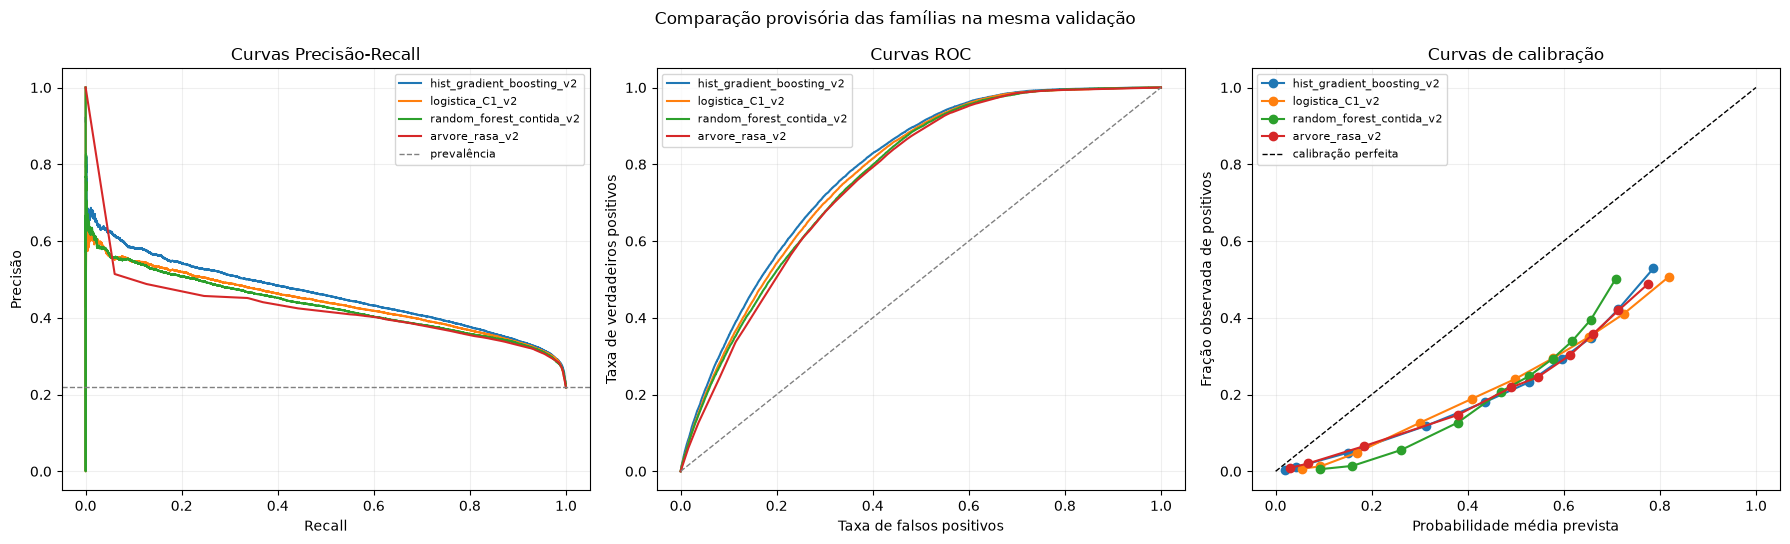

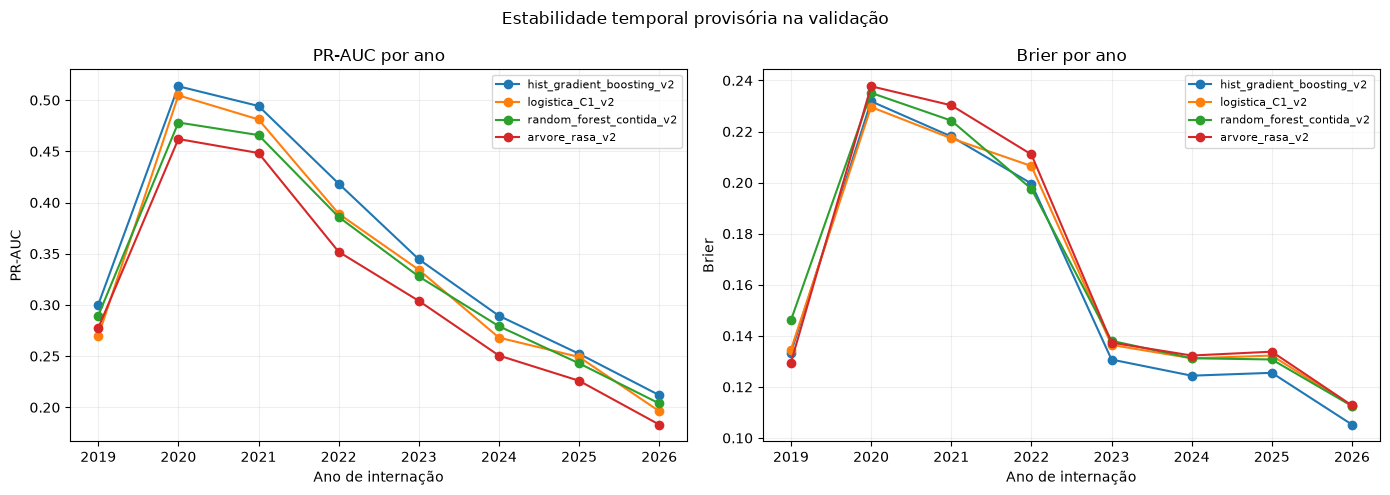

,modelo,ano_internacao,n,positivos,prevalencia,pr_auc,roc_auc,brier,probabilidade_media
0,arvore_rasa_v2,2019,1333,160,0.120030,0.277375,0.768185,0.129544,0.239494
1,arvore_rasa_v2,2020,30032,8402,0.279768,0.462044,0.729951,0.237736,0.518322
2,arvore_rasa_v2,2021,45369,12790,0.281911,0.448374,0.714009,0.230279,0.496664
3,arvore_rasa_v2,2022,14589,2649,0.181575,0.351895,0.765021,0.211041,0.424400
4,arvore_rasa_v2,2023,7378,706,0.095690,0.303971,0.844782,0.137340,0.277328
5,arvore_rasa_v2,2024,7033,586,0.083321,0.250566,0.829883,0.132291,0.260034
6,arvore_rasa_v2,2025,8886,650,0.073149,0.225946,0.826649,0.133800,0.258650
7,arvore_rasa_v2,2026,5380,299,0.055576,0.183159,0.829359,0.112745,0.219590
8,dummy_prior_v2,2019,1333,160,0.120030,0.120030,0.500000,0.115355,0.218683
9,dummy_prior_v2,2020,30032,8402,0.279768,0.279768,0.500000,0.205229,0.218683


,modelo,pr_auc_min,pr_auc_max,pr_auc_media,roc_auc_min,roc_auc_max,brier_min,brier_max,amplitude_pr_auc,amplitude_roc_auc
0,random_forest_contida_v2,0.203790,0.478153,0.334150,0.716818,0.848000,0.112521,0.235140,0.274363,0.131182
1,arvore_rasa_v2,0.183159,0.462044,0.312916,0.714009,0.844782,0.112745,0.237736,0.278885,0.130772
2,hist_gradient_boosting_v2,0.211900,0.513565,0.353089,0.738849,0.857779,0.105253,0.231840,0.301665,0.118930
3,logistica_C1_v2,0.196244,0.504676,0.336532,0.729530,0.850611,0.112566,0.229609,0.308432,0.121081


Figuras gravadas:
- C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\reports\figures\supervisionado_03\03_pilotos_curvas_pr_roc_calibracao.png
- C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\reports\figures\supervisionado_03\03_pilotos_metricas_por_ano.png


In [29]:
# ============================================================
# 23. Diagnósticos de discriminação, calibração e estabilidade anual
# ============================================================

import matplotlib.pyplot as plt

from sklearn.calibration import calibration_curve
from sklearn.metrics import precision_recall_curve, roc_curve


FIGURES_DIR = ROOT_DIR / "reports" / "figures" / "supervisionado_03"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

modelos_avaliaveis = (
    resultados_cinco_familias.loc[
        resultados_cinco_familias["modelo"].ne("dummy_prior_v2"),
        "modelo",
    ]
    .tolist()
)

figura_curvas, eixos_curvas = plt.subplots(
    1,
    3,
    figsize=(18, 5.5),
)

prevalencia_validacao_piloto = float(
    y_validacao_piloto.mean()
)

for modelo in modelos_avaliaveis:
    dados_modelo = predicoes_cinco_familias_df.loc[
        predicoes_cinco_familias_df["modelo"].eq(modelo)
    ]

    precisao, recall, _ = precision_recall_curve(
        dados_modelo["y_true"],
        dados_modelo["y_prob"],
    )

    falso_positivo, verdadeiro_positivo, _ = roc_curve(
        dados_modelo["y_true"],
        dados_modelo["y_prob"],
    )

    fracao_positivos, media_prevista = calibration_curve(
        dados_modelo["y_true"],
        dados_modelo["y_prob"],
        n_bins=10,
        strategy="quantile",
    )

    eixos_curvas[0].plot(
        recall,
        precisao,
        label=modelo,
    )

    eixos_curvas[1].plot(
        falso_positivo,
        verdadeiro_positivo,
        label=modelo,
    )

    eixos_curvas[2].plot(
        media_prevista,
        fracao_positivos,
        marker="o",
        label=modelo,
    )


eixos_curvas[0].axhline(
    prevalencia_validacao_piloto,
    linestyle="--",
    color="gray",
    linewidth=1,
    label="prevalência",
)
eixos_curvas[0].set_title("Curvas Precisão-Recall")
eixos_curvas[0].set_xlabel("Recall")
eixos_curvas[0].set_ylabel("Precisão")

eixos_curvas[1].plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    linewidth=1,
)
eixos_curvas[1].set_title("Curvas ROC")
eixos_curvas[1].set_xlabel("Taxa de falsos positivos")
eixos_curvas[1].set_ylabel("Taxa de verdadeiros positivos")

eixos_curvas[2].plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="black",
    linewidth=1,
    label="calibração perfeita",
)
eixos_curvas[2].set_title("Curvas de calibração")
eixos_curvas[2].set_xlabel("Probabilidade média prevista")
eixos_curvas[2].set_ylabel("Fração observada de positivos")

for eixo in eixos_curvas:
    eixo.grid(alpha=0.2)
    eixo.legend(fontsize=8)

figura_curvas.suptitle(
    "Comparação provisória das famílias na mesma validação"
)
figura_curvas.tight_layout()

caminho_figura_curvas = (
    FIGURES_DIR
    / "03_pilotos_curvas_pr_roc_calibracao.png"
)
figura_curvas.savefig(
    caminho_figura_curvas,
    dpi=160,
    bbox_inches="tight",
    facecolor="white",
)
plt.show()
plt.close(figura_curvas)


metricas_por_ano = []

for (modelo, ano), grupo in (
    predicoes_cinco_familias_df.groupby(
        ["modelo", "ano_internacao"],
        sort=True,
        observed=True,
    )
):
    y_ano = grupo["y_true"].to_numpy(dtype=np.int8)
    prob_ano = grupo["y_prob"].to_numpy(dtype=float)

    if np.unique(y_ano).size < 2:
        roc_auc_ano = np.nan
        pr_auc_ano = np.nan
    else:
        roc_auc_ano = float(
            roc_auc_score(y_ano, prob_ano)
        )
        pr_auc_ano = float(
            average_precision_score(y_ano, prob_ano)
        )

    metricas_por_ano.append(
        {
            "modelo": modelo,
            "ano_internacao": int(ano),
            "n": int(len(grupo)),
            "positivos": int(y_ano.sum()),
            "prevalencia": float(y_ano.mean()),
            "pr_auc": pr_auc_ano,
            "roc_auc": roc_auc_ano,
            "brier": float(
                brier_score_loss(y_ano, prob_ano)
            ),
            "probabilidade_media": float(prob_ano.mean()),
        }
    )

metricas_por_ano_df = pd.DataFrame(
    metricas_por_ano
)

variacao_temporal_modelos = (
    metricas_por_ano_df.loc[
        metricas_por_ano_df["modelo"].ne("dummy_prior_v2")
    ]
    .groupby("modelo", observed=True)
    .agg(
        pr_auc_min=("pr_auc", "min"),
        pr_auc_max=("pr_auc", "max"),
        pr_auc_media=("pr_auc", "mean"),
        roc_auc_min=("roc_auc", "min"),
        roc_auc_max=("roc_auc", "max"),
        brier_min=("brier", "min"),
        brier_max=("brier", "max"),
    )
    .reset_index()
)

variacao_temporal_modelos["amplitude_pr_auc"] = (
    variacao_temporal_modelos["pr_auc_max"]
    - variacao_temporal_modelos["pr_auc_min"]
)

variacao_temporal_modelos["amplitude_roc_auc"] = (
    variacao_temporal_modelos["roc_auc_max"]
    - variacao_temporal_modelos["roc_auc_min"]
)

figura_temporal, eixos_temporais = plt.subplots(
    1,
    2,
    figsize=(14, 5),
)

for modelo in modelos_avaliaveis:
    dados_modelo = metricas_por_ano_df.loc[
        metricas_por_ano_df["modelo"].eq(modelo)
    ].sort_values("ano_internacao")

    eixos_temporais[0].plot(
        dados_modelo["ano_internacao"],
        dados_modelo["pr_auc"],
        marker="o",
        label=modelo,
    )

    eixos_temporais[1].plot(
        dados_modelo["ano_internacao"],
        dados_modelo["brier"],
        marker="o",
        label=modelo,
    )


eixos_temporais[0].set_title("PR-AUC por ano")
eixos_temporais[0].set_xlabel("Ano de internação")
eixos_temporais[0].set_ylabel("PR-AUC")

eixos_temporais[1].set_title("Brier por ano")
eixos_temporais[1].set_xlabel("Ano de internação")
eixos_temporais[1].set_ylabel("Brier")

for eixo in eixos_temporais:
    eixo.grid(alpha=0.2)
    eixo.legend(fontsize=8)

figura_temporal.suptitle(
    "Estabilidade temporal provisória na validação"
)
figura_temporal.tight_layout()

caminho_figura_temporal = (
    FIGURES_DIR
    / "03_pilotos_metricas_por_ano.png"
)
figura_temporal.savefig(
    caminho_figura_temporal,
    dpi=160,
    bbox_inches="tight",
    facecolor="white",
)
plt.show()
plt.close(figura_temporal)


display(
    metricas_por_ano_df.sort_values(
        ["modelo", "ano_internacao"]
    ).reset_index(drop=True)
)

display(
    variacao_temporal_modelos.sort_values(
        ["amplitude_pr_auc", "pr_auc_media"],
        ascending=[True, False],
    ).reset_index(drop=True)
)

print("Figuras gravadas:")
print("-", caminho_figura_curvas)
print("-", caminho_figura_temporal)


In [30]:
# ============================================================
# 24. Persistir a comparação provisória e registrar o próximo gate
# ============================================================

import json


timestamp_comparacao = pd.Timestamp.now(
    tz="UTC"
).strftime("%Y%m%dT%H%M%SZ")

prefixo_comparacao = (
    f"03_cinco_familias_{STATUS_COORTE}_"
    f"{timestamp_comparacao}"
)

caminho_resultados_cinco = (
    Path(TABLES_DIR)
    / f"{prefixo_comparacao}_metricas.csv"
)

caminho_metricas_ano = (
    Path(TABLES_DIR)
    / f"{prefixo_comparacao}_metricas_por_ano.csv"
)

caminho_variacao_temporal = (
    Path(TABLES_DIR)
    / f"{prefixo_comparacao}_variacao_temporal.csv"
)

caminho_amostras = (
    Path(TABLES_DIR)
    / f"{prefixo_comparacao}_amostras.csv"
)

caminho_predicoes_cinco = (
    Path(PREDICTIONS_DIR)
    / f"{prefixo_comparacao}_predicoes_validacao.parquet"
)

caminho_manifesto_cinco = (
    Path(TABLES_DIR)
    / f"{prefixo_comparacao}_manifesto.json"
)

resultados_cinco_familias.to_csv(
    caminho_resultados_cinco,
    index=False,
    encoding="utf-8-sig",
)

metricas_por_ano_df.to_csv(
    caminho_metricas_ano,
    index=False,
    encoding="utf-8-sig",
)

variacao_temporal_modelos.to_csv(
    caminho_variacao_temporal,
    index=False,
    encoding="utf-8-sig",
)

resumo_amostras_comparacao.to_csv(
    caminho_amostras,
    index=False,
    encoding="utf-8-sig",
)

predicoes_cinco_familias_df.to_parquet(
    caminho_predicoes_cinco,
    index=False,
)


ranking_provisorio = (
    resultados_cinco_familias.loc[
        resultados_cinco_familias["modelo"].ne("dummy_prior_v2")
    ]
    .copy()
    .sort_values(
        ["pr_auc", "brier", "duracao_fit_s"],
        ascending=[False, True, True],
    )
    .reset_index(drop=True)
)

shortlist_provisoria = ranking_provisorio.head(2)[
    "modelo"
].tolist()

manifesto_cinco = {
    "status_coorte": STATUS_COORTE,
    "versao_execucao": VERSAO_COMPARACAO,
    "carater": "comparacao_provisoria_de_integracao",
    "seed": int(SEED),
    "n_treino_piloto": int(len(X_treino_piloto)),
    "n_validacao_piloto": int(len(X_validacao_piloto)),
    "features": list(FEATURES_PILOTO),
    "modelos": list(modelos_piloto.keys()),
    "shortlist_provisoria": shortlist_provisoria,
    "teste_aberto": False,
    "limiar_selecionado": False,
    "calibracao_aplicada": False,
    "tuning_realizado": False,
    "observacoes": [
        "Resultados dependem da coorte provisória.",
        "Amostras comparáveis foram usadas para controlar custo.",
        "A shortlist não congela finalistas.",
        "O teste permaneceu fechado.",
        "Calibração e limiar pertencem à próxima etapa.",
    ],
    "artefatos": {
        "metricas": str(caminho_resultados_cinco),
        "metricas_por_ano": str(caminho_metricas_ano),
        "variacao_temporal": str(caminho_variacao_temporal),
        "amostras": str(caminho_amostras),
        "predicoes_validacao": str(caminho_predicoes_cinco),
        "figura_curvas": str(caminho_figura_curvas),
        "figura_temporal": str(caminho_figura_temporal),
    },
}

caminho_manifesto_cinco.write_text(
    json.dumps(
        manifesto_cinco,
        indent=2,
        ensure_ascii=False,
        default=str,
    ),
    encoding="utf-8",
)


# Round-trip dos principais artefatos.
resultados_reabertos = pd.read_csv(
    caminho_resultados_cinco,
    encoding="utf-8-sig",
)

predicoes_reabertas = pd.read_parquet(
    caminho_predicoes_cinco
)

manifesto_reaberto_cinco = json.loads(
    caminho_manifesto_cinco.read_text(
        encoding="utf-8"
    )
)

validacoes_comparacao = {
    "cinco_modelos_registrados": len(resultados_reabertos) == 5,
    "cinco_modelos_com_predicoes": predicoes_reabertas["modelo"].nunique() == 5,
    "probabilidades_validas": predicoes_reabertas["y_prob"].between(0, 1).all(),
    "teste_permaneceu_fechado": manifesto_reaberto_cinco["teste_aberto"] is False,
    "status_provisorio": manifesto_reaberto_cinco["status_coorte"] == "provisoria",
    "sem_tuning": manifesto_reaberto_cinco["tuning_realizado"] is False,
    "sem_limiar_final": manifesto_reaberto_cinco["limiar_selecionado"] is False,
    "figuras_existentes": caminho_figura_curvas.exists() and caminho_figura_temporal.exists(),
}

validacoes_comparacao_df = pd.DataFrame(
    {
        "verificacao": validacoes_comparacao.keys(),
        "resultado": validacoes_comparacao.values(),
    }
)

display(validacoes_comparacao_df)

if not all(validacoes_comparacao.values()):
    falhas = [
        chave
        for chave, valor in validacoes_comparacao.items()
        if not valor
    ]
    raise RuntimeError(
        "Falhas na comparação provisória: "
        f"{falhas}"
    )

print("Shortlist provisória, sem congelamento:", shortlist_provisoria)
print("Artefatos da comparação gravados com sucesso.")
print("O teste permaneceu fechado.")
print("Próximo gate: coorte definitiva, features congeladas, tuning limitado, calibração e limiar.")


,verificacao,resultado
0,cinco_modelos_registrados,True
1,cinco_modelos_com_predicoes,True
2,probabilidades_validas,True
3,teste_permaneceu_fechado,True
4,status_provisorio,True
5,sem_tuning,True
6,sem_limiar_final,True
7,figuras_existentes,True


Shortlist provisória, sem congelamento: ['hist_gradient_boosting_v2', 'logistica_C1_v2']
Artefatos da comparação gravados com sucesso.
O teste permaneceu fechado.
Próximo gate: coorte definitiva, features congeladas, tuning limitado, calibração e limiar.


# Conclusão provisória ampliada

Esta execução confirmou que o fluxo supervisionado provisório funciona ponta a ponta e permitiu comparar, sob a mesma amostra de treino e validação:

- baseline Dummy;
- regressão logística;
- árvore de decisão rasa;
- Random Forest com configuração contida;
- HistGradientBoosting com configuração contida.

A comparação utiliza a mesma lista provisória de features, as mesmas partições e a mesma amostra estratificada por ano e alvo. Imputação, codificação e escala foram ajustadas somente no treino de cada pipeline.

Os resultados continuam provisórios. A tabela comparativa serve para verificar viabilidade, custo, discriminação, calibração e estabilidade temporal das famílias, mas não congela modelo final, hiperparâmetros, limiar ou método de calibração.

As curvas de Precisão-Recall e ROC avaliam discriminação na validação. A curva de calibração compara probabilidades previstas com a frequência observada, sem que qualquer correção de calibração tenha sido aplicada nesta etapa.

A avaliação por ano deve ser interpretada como diagnóstico de robustez interna. Variações de PR-AUC, ROC-AUC ou Brier entre 2019 e 2026 podem refletir mudanças epidemiológicas, demográficas, de cobertura e de documentação já identificadas nas EDAs. O ano de 2026 permanece parcial.

A shortlist gerada é apenas operacional. Ela identifica até duas famílias para continuidade técnica, mas deverá ser recalculada depois da chegada da coorte definitiva e do congelamento da seleção final de colunas.

As curvas de calibração permaneceram predominantemente abaixo da diagonal de referência, indicando superestimação das probabilidades observadas em parte relevante da distribuição. Esse comportamento é compatível com o caráter ainda não calibrado dos pilotos e pode ser influenciado pelo uso de pesos balanceados. Por isso, as probabilidades brutas não devem ser interpretadas como riscos absolutos nesta etapa. Brier, PR-AUC e ROC-AUC serão avaliados conjuntamente após o ajuste limitado dos finalistas.

A redução da PR-AUC nos anos mais recentes não deve ser interpretada isoladamente como deterioração do modelo, pois a métrica depende da prevalência e da composição de cada período. A estabilidade temporal será reavaliada com a coorte definitiva, mantendo 2026 identificado como período parcial.

O conjunto de teste permaneceu fechado durante toda a comparação. Não houve tuning, escolha de limiar, calibração, análise final por subgrupo nem interpretação definitiva de importância de variáveis.

## Próximo gate

A próxima etapa somente deverá começar após:

1. recebimento e validação da coorte definitiva;
2. congelamento da lista final de features;
3. reprodução ou importação da partição oficial;
4. confirmação da ausência de vazamento;
5. repetição dos pilotos comparáveis;
6. escolha de no máximo dois finalistas;
7. tuning limitado no treino;
8. confirmação na validação;
9. calibração e escolha de limiar sem acesso ao teste.
